# Равновесная энергия в магнитном кольце `magnetic_2`: разбор шагов 1–7
Исследование `studies/magnetic_ring`: кольцо `magnetic_2` (дейтрон, 270 МэВ, $h=1$) на текущем API BELL, физика — главы 1–3
`notes/equilibrium-energy-v3`. Главная величина — сдвиг равновесного импульса
$$\delta_{eq}=-\frac{\eta_1\langle\delta^2\rangle+\Lambda}{\eta_0},\qquad \langle\delta^2\rangle=\frac{\delta_m^2}{2},\qquad
\Lambda=-\frac{2\pi}{C}\left(J_x\xi_x+J_y\xi_y\right),$$
и производные от него $\gamma_{eff}=\gamma+\beta^2\gamma\,\delta_{eq}+\beta^2\langle\delta^2\rangle/(2\gamma)$, $\Delta E/E$.
Оптика, хроматичность, slip и расстройка читаются из факторов Ли (гамильтониан → Драгт–Финн); трекинг и DA — только перекрёстная проверка.

Каждый шаг: физическая преамбула → скрипт шага и его отчёт → таблицы и рисунки из `output/` → выводы по рисункам.
По умолчанию тетрадь читает сохранённые результаты прогонов; `RUN_JULIA=1` перед запуском Jupyter перезапускает скрипты
(короткие значения по умолчанию, шаг 7 ≈ 13 мин) и печатает их вывод. Ни одно число здесь не подгоняется: всё прочитано из прогонов.

In [1]:
import os, json, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, SVG, display
OUT = Path('output'); RUN_JULIA = os.environ.get('RUN_JULIA') == '1'
pd.set_option('display.float_format', '{:.6g}'.format); pd.set_option('display.max_rows', 200)

def header(script):
    lines = Path('scripts', script).read_text(encoding='utf-8').splitlines()
    return '\n'.join(l for l in lines[:next(i for i, l in enumerate(lines) if not l.startswith('#'))])

def run_step(script, report):
    print(header(script), end='\n\n')
    if RUN_JULIA:
        cmd = ['julia', '--project=.', f'scripts/{script}']; print('$', ' '.join(cmd), flush=True)
        with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace') as p:
            for line in p.stdout: print(line, end='', flush=True)
        if p.returncode: raise RuntimeError(f'{script} exited with {p.returncode}')
    else:
        print(f'RUN_JULIA не задан: показан сохранённый отчёт output/{report}.')
    text = (OUT / report).read_text(encoding='utf-8')
    display(Markdown(f'<details><summary><b>Отчёт <code>output/{report}</code></b></summary>\n\n{text}\n\n</details>'))

def kv(name):
    df = pd.read_csv(OUT / name); return dict(zip(df.quantity, df.value))

seq = pd.read_csv(OUT / 'sequence.csv'); seq['s1'] = seq.length_m.cumsum(); seq['s0'] = seq.s1 - seq.length_m; seq['sc'] = (seq.s0 + seq.s1) / 2
opt = pd.read_csv(OUT / '02_optics.csv'); at = lambda col, s: np.interp(s, opt.s_m, opt[col])
CIRC = seq.s1.iloc[-1]
FAM = {'SXD': seq[seq.name == 'SF1'], 'SXB': seq[seq.name == 'SF2'],
       'SYB': seq[seq.name.isin(['SD', 'OS1']) & (at('Dx_m', seq.sc) > 0.5)]}

## 1. Решётка: замыкание поворота до $2\pi$
Замкнутая орбита существует, только если суммарный угол поворота равен $2\pi$. В исходном файле угол BM записан как
`0.3926990753258494`, что на $6.4\cdot10^{-9}$ рад меньше $\pi/8$; шестнадцать магнитов недогибают на $\Delta\theta\approx1.0\cdot10^{-7}$ рад.
Однородный недогиб эквивалентен сдвигу опорного импульса порядка $\Delta\theta/2\pi\approx1.6\cdot10^{-8}$ — того же порядка, что искомый
$\delta_{eq}\sim10^{-8}$. Поэтому угол каждого BM ставится ровно $\pi/8$ (длина дуги не меняется, $C$ тоже), и замкнутая решётка
сохраняется в `lattices/magnetic_2_closed.bell`.

In [2]:
run_step('01_lattice.jl', '01_lattice.md')

# Step 1. Write the magnetic_2 element table and close the sector bends.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/01_lattice.jl

RUN_JULIA не задан: показан сохранённый отчёт output/01_lattice.md.


<details><summary><b>Отчёт <code>output/01_lattice.md</code></b></summary>

# magnetic_2 lattice closed to 2π

Source file (read-only): `C:/GIT_REPOS/BELL/examples/lattices/magnetic_2.bell`.

The file token on the BM card is `0.3926990753258494`. Loaded as a Float64 it is 0.3926990753258494. Sixteen equal sector bends therefore sum to 6.283185205213589, which is -1.0196599742329227e-7 relative to 2π. `OBM` is a drift of the same length and is left unchanged. Every BM angle in the closed ring is the Float64 value of π/8, 0.39269908169872414. `total_bend_angle` of that ring is 6.283185307179588, which differs from 2π by 1.7763568394002505e-15. The product 16 * (π/8) differs from 2π by 0.0.

Closed lattice: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Reloading that file reproduces the in-memory closed ring, including the reference particle. A separate `write_structure` round trip does not: element-wise match false, BM angle change -5.551115123125783e-17 rad on each of 16 bends, total_bend_angle change -4.440892098500626e-15 rad. That bend change is not 16 times the angle change: total_bend_angle reduces over the whole element list. Path-length change 0.0 m, other element mismatches 0, reference match true. The saved lattice is the edited copy, not the `write_structure` text.

Counts: 16 BM, 4 OBM, shared length 5.329414799999999 m, 84 elements in sequence. Reference: deuteron, kinetic energy 270.0 MeV, harmonic 1.

`Qx` and `Qy` are accumulated tunes from `optics_along` (integer part included). `Qx_frac` and `Qy_frac` are μ/2π from `periodic_optics` of `ring_matrix`. Open-ring fractional closure residuals: Qx 5.717648576819556e-15, Qy 1.1213252548714081e-14. Closed-ring residuals: Qx 7.827072323607354e-15, Qy 1.1213252548714081e-14. Symplectic error of the one-turn matrix: open 3.201432791984271e-14, closed 2.0714340087555213e-14.

Path length is the sum of element lengths. The arc length of BM is not changed, so the circumference does not change.

## Closure

| quantity | before | after | delta |
| --- | --- | --- | --- |
| bm_angle_rad | 0.3926990753258494 | 0.39269908169872414 | 6.372874727933464e-9 |
| total_bend_angle_rad | 6.283185205213589 | 6.283185307179588 | 1.019659991996491e-7 |
| total_bend_minus_2pi_rad | -1.0196599742329227e-7 | 1.7763568394002505e-15 | 1.019659991996491e-7 |
| path_length_m | 117.38829599999988 | 117.38829599999988 | 0.0 |
| Qx | 2.4617201386366054 | 2.4617201498667933 | 1.1230187890731713e-8 |
| Qy | 2.4613373230490914 | 2.4613373230490914 | 0.0 |
| Qx_frac | 0.4617201386365997 | 0.46172014986680116 | 1.1230201435452614e-8 |
| Qy_frac | 0.46133732304908015 | 0.46133732304908015 | 0.0 |

## Unique elements

| name | count | type | length_m | angle_open_rad | angle_closed_rad | k1 | k2 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| OS2 | 8 | Drift | 0.06 |  |  |  |  |
| QF | 16 | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| BM | 16 | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| QD | 16 | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| OS1 | 6 | Drift | 0.12 |  |  |  |  |
| SF2 | 4 | Sextupole | 0.12 |  |  |  | 0.0 |
| SD | 4 | Sextupole | 0.12 |  |  |  | 0.0 |
| SF1 | 2 | Sextupole | 0.12 |  |  |  | 0.0 |
| QF1 | 4 | Quadrupole | 0.21 |  |  | 0.5565959259588208 |  |
| OBM | 4 | Drift | 5.329414799999999 |  |  |  |  |
| QD1 | 4 | Quadrupole | 0.21 |  |  | -0.5565959259588208 |  |

## Sequence

| index | name | type | length_m | angle_open_rad | angle_closed_rad | k1 | k2 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | OS2 | Drift | 0.06 |  |  |  |  |
| 2 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 3 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 4 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 5 | OS1 | Drift | 0.12 |  |  |  |  |
| 6 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 7 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 8 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 9 | SF2 | Sextupole | 0.12 |  |  |  | 0.0 |
| 10 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 11 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 12 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 13 | SD | Sextupole | 0.12 |  |  |  | 0.0 |
| 14 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 15 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 16 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 17 | SF1 | Sextupole | 0.12 |  |  |  | 0.0 |
| 18 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 19 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 20 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 21 | SD | Sextupole | 0.12 |  |  |  | 0.0 |
| 22 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 23 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 24 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 25 | SF2 | Sextupole | 0.12 |  |  |  | 0.0 |
| 26 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 27 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 28 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 29 | OS1 | Drift | 0.12 |  |  |  |  |
| 30 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 31 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 32 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 33 | OS2 | Drift | 0.06 |  |  |  |  |
| 34 | OS2 | Drift | 0.06 |  |  |  |  |
| 35 | QF1 | Quadrupole | 0.21 |  |  | 0.5565959259588208 |  |
| 36 | OBM | Drift | 5.329414799999999 |  |  |  |  |
| 37 | QD1 | Quadrupole | 0.21 |  |  | -0.5565959259588208 |  |
| 38 | OS1 | Drift | 0.12 |  |  |  |  |
| 39 | QD1 | Quadrupole | 0.21 |  |  | -0.5565959259588208 |  |
| 40 | OBM | Drift | 5.329414799999999 |  |  |  |  |
| 41 | QF1 | Quadrupole | 0.21 |  |  | 0.5565959259588208 |  |
| 42 | OS2 | Drift | 0.06 |  |  |  |  |
| 43 | OS2 | Drift | 0.06 |  |  |  |  |
| 44 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 45 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 46 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 47 | OS1 | Drift | 0.12 |  |  |  |  |
| 48 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 49 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 50 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 51 | SF2 | Sextupole | 0.12 |  |  |  | 0.0 |
| 52 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 53 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 54 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 55 | SD | Sextupole | 0.12 |  |  |  | 0.0 |
| 56 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 57 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 58 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 59 | SF1 | Sextupole | 0.12 |  |  |  | 0.0 |
| 60 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 61 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 62 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 63 | SD | Sextupole | 0.12 |  |  |  | 0.0 |
| 64 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 65 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 66 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 67 | SF2 | Sextupole | 0.12 |  |  |  | 0.0 |
| 68 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 69 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 70 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 71 | OS1 | Drift | 0.12 |  |  |  |  |
| 72 | QD | Quadrupole | 0.21 |  |  | -0.5805856428570646 |  |
| 73 | BM | SBend | 5.329414799999999 | 0.3926990753258494 | 0.39269908169872414 | 0.0 |  |
| 74 | QF | Quadrupole | 0.21 |  |  | 0.5212441755015996 |  |
| 75 | OS2 | Drift | 0.06 |  |  |  |  |
| 76 | OS2 | Drift | 0.06 |  |  |  |  |
| 77 | QF1 | Quadrupole | 0.21 |  |  | 0.5565959259588208 |  |
| 78 | OBM | Drift | 5.329414799999999 |  |  |  |  |
| 79 | QD1 | Quadrupole | 0.21 |  |  | -0.5565959259588208 |  |
| 80 | OS1 | Drift | 0.12 |  |  |  |  |
| 81 | QD1 | Quadrupole | 0.21 |  |  | -0.5565959259588208 |  |
| 82 | OBM | Drift | 5.329414799999999 |  |  |  |  |
| 83 | QF1 | Quadrupole | 0.21 |  |  | 0.5565959259588208 |  |
| 84 | OS2 | Drift | 0.06 |  |  |  |  |



</details>

,before,after,delta
quantity,,,
bm_angle_rad,0.392699,0.392699,6.37287e-09
total_bend_angle_rad,6.28319,6.28319,1.01966e-07
total_bend_minus_2pi_rad,-1.01966e-07,1.77636e-15,1.01966e-07
path_length_m,117.388,117.388,0
Qx,2.46172,2.46172,1.12302e-08
Qy,2.46134,2.46134,0
Qx_frac,0.46172,0.46172,1.12302e-08
Qy_frac,0.461337,0.461337,0


недогиб Δθ = 1.020e-07 рад, Δθ/2π = 1.623e-08


,name,count,type,length_m,angle_open_rad,angle_closed_rad,k1,k2
0,OS2,8,Drift,0.06,NaN,NaN,NaN,NaN
1,QF,16,Quadrupole,0.21,NaN,NaN,0.521244,NaN
2,BM,16,SBend,5.32941,0.392699,0.392699,0,NaN
3,QD,16,Quadrupole,0.21,NaN,NaN,-0.580586,NaN
4,OS1,6,Drift,0.12,NaN,NaN,NaN,NaN
5,SF2,4,Sextupole,0.12,NaN,NaN,NaN,0
6,SD,4,Sextupole,0.12,NaN,NaN,NaN,0
7,SF1,2,Sextupole,0.12,NaN,NaN,NaN,0
8,QF1,4,Quadrupole,0.21,NaN,NaN,0.556596,NaN
9,OBM,4,Drift,5.32941,NaN,NaN,NaN,NaN


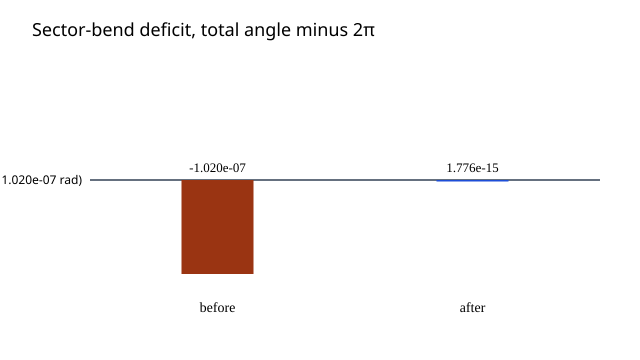

In [3]:
cl = pd.read_csv(OUT / 'closure.csv', index_col=0); display(cl)
dth = -cl.loc['total_bend_minus_2pi_rad', 'before']
print(f'недогиб Δθ = {dth:.3e} рад, Δθ/2π = {dth / (2 * np.pi):.3e}')
display(pd.read_csv(OUT / 'unique_elements.csv'))
display(SVG(filename=str(OUT / 'bend_deficit.svg')))

**Рисунок 1.** Суммарный угол поворота минус $2\pi$ до и после замыкания: $-1.02\cdot10^{-7}$ рад → $1.8\cdot10^{-15}$ рад (округление Float64).

**Выводы.** После замыкания поворот равен $2\pi$ до машинной точности, $\Delta C=0$, $Q_x$ сдвинулся на $1.1\cdot10^{-8}$, $Q_y$ не изменился.
Без этой правки ошибка геометрии была бы сравнима с самим $\delta_{eq}$. Побочная находка: `write_structure` не сохраняет угол бит в бит
($-5.6\cdot10^{-17}$ рад на магнит), поэтому записан отредактированный объект, а не текст `write_structure` (BELL issue #64; угол — #63).

## 2. Линейная оптика и выбор режимов ВЧ
Из фактора Ли и матрицы одного оборота: функции Твисса, тюны, дисперсия и коэффициенты slip
$$\alpha_0=\frac1C\oint\frac{D_x}{\rho}\,ds,\qquad \eta_0=\alpha_0-\frac1{\gamma^2},\qquad
\eta_1=\alpha_1-\frac{\alpha_0}{\gamma^2}+\frac{3\gamma^2-1}{2\gamma^4},\qquad \gamma_t=\alpha_0^{-1/2}.$$
При $\gamma=1.144<\gamma_t$ кольцо работает ниже критической энергии, $\eta_0<0$. В обозначениях BELL поздний приход — $l>0$,
поэтому стационарная фаза полости в BELL $\phi_s^B=\pi$ (в заметках $\phi_s^N=0$, словарь $\phi^B=-\phi^N$).
Синхротронный тюн и амплитуда фазы малых колебаний:
$$Q_s=\sqrt{\frac{h\,eV\,|\eta_0\cos\phi_s|}{2\pi\beta^2E}},\qquad \hat\phi=\frac{h|\eta_0|}{Q_s}\,\delta_m.$$
Два режима при $h=1$, $\delta_m=10^{-4}$: «линейный» $\hat\phi=0.05$ и «кубический» $\hat\phi=0.3$, где поправка
$1-\hat\phi^2/32$ к $\langle\delta^2\rangle$ (глава 3) различима. Оба удовлетворяют неравенствам заметок:
$|\eta_1\delta_m/\eta_0|$, $|\Lambda/(\eta_0\delta_m)|$, $\omega_sT_s\ll1$.

In [4]:
run_step('02_linear_optics.jl', '02_linear_optics.md')

# Step 2. Linear optics of the closed magnetic_2 ring, from the Lie factor
# and from the one-turn matrix. Choose two stationary RF regimes.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/02_linear_optics.jl

RUN_JULIA не задан: показан сохранённый отчёт output/02_linear_optics.md.


<details><summary><b>Отчёт <code>output/02_linear_optics.md</code></b></summary>

# Linear optics of closed magnetic_2

Lattice file: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Every sextupole has `k2 = 0`. Reference: deuteron, kinetic energy 270.0 MeV, charge number 1.0, harmonic 1.

gamma = 1.14395294, beta = 0.48563473, total energy = 2145.612943 MeV, brho = 3.475685 T m.

The one-turn matrix is `ring_matrix` (`linear_matrix` of each element, `R = exp(L S Hess H)`). The polynomial is `path_expansion` of `observables`, which builds `ring_lie_factor`. `periodic_optics` is taken on the matrix and on the Lie factor `R`. `optics_along` transports the matrix Twiss. Where two readings name the same quantity, both are printed and the run stops if they differ by more than 1.0e-8. Nothing was averaged and nothing was tuned.

Largest |matrix − Lie R| and the slip, compaction, and tune residuals are below 1.0e-08. Symplectic error of the matrix is 2.071e-14. `eta1` matches `eta1_formula` from the same expansion. `(1/C) ∫ D/ρ ds` differs from `alpha0` by 8.940e-08.

## One-turn numbers

`Qx` and `Qy` include the integer from `optics_along`. Fractional tunes are `mu/2π` from `periodic_optics` of the matrix. `alpha0`, `eta0`, `eta1`, and `gamma_t` are from `path_expansion`.

| quantity | value |
| --- | --- |
| C [m] | 1.17388296e+02 |
| Qx | 2.46172015e+00 |
| Qy | 2.46133732e+00 |
| Qx fractional | 4.61720150e-01 |
| Qy fractional | 4.61337323e-01 |
| alpha0 | 2.30470282e-01 |
| alpha1 | 3.39007701e-01 |
| eta0 | -5.33688628e-01 |
| eta1 | 1.01716073e+00 |
| gamma_t | 2.08301565e+00 |
| 1/gamma^2 | 7.64158910e-01 |
| (1/C) int D/rho ds | 2.30470372e-01 |
| beta_x(0) [m] | 1.93675224e+01 |
| alpha_x(0) | -2.51911777e-04 |
| beta_y(0) [m] | 4.05447047e+00 |
| alpha_y(0) | -1.88150489e-04 |
| D_x(0) [m] | 1.10941104e-02 |
| D_x'(0) | -5.06166051e-04 |
| D_y(0) [m] | 0.00000000e+00 |
| D_y'(0) | 0.00000000e+00 |
| max abs(D_y) [m] | 0.00000000e+00 |
| max abs(D_y') | 0.00000000e+00 |
| max beta_x [m] | 1.93677385e+01 |
| max beta_y [m] | 1.93646410e+01 |
| max D_x [m] | 1.17016103e+01 |
| min D_x [m] | 6.77386256e-03 |

Closure of `optics_along` (relative beta, absolute alpha, absolute dispersion, fractional tune):

| quantity | residual |
| --- | --- |
| betx | 4.58591657e-15 |
| alfx | 1.04063351e-14 |
| bety | 1.11721370e-14 |
| alfy | 2.07832341e-14 |
| D | 1.58884711e-12 |
| Dp | 4.81604773e-14 |
| Qx_frac | 7.82707232e-15 |
| Qy_frac | 1.12132525e-14 |

## Cell phase advance

An arc cell is the repeated block `QF BM QD (L = 0.12) QD BM QF` closed by one `L = 0.12` element, or by two `OS2` drifts where that element is split. Sextupoles are at `k2 = 0`. The in-ring phase is the advance of `optics_along` from the cell entrance to the cell exit. It is not set to 90 degrees. The periodic column is `mu` of `periodic_optics` on that cell's own matrix. Those two phases answer different questions: the periodic column assumes the cell is repeated by itself, and the in-ring column is the advance inside this ring, straights included in the periodic Twiss.

In-ring mean: mu_x = 1.57150893 rad (90.0408 deg), mu_y = 1.57122422 rad (90.0245 deg). Spread max−min: 1.347e-03 rad in x, 6.694e-03 rad in y.

| cell | s_start [m] | s_end [m] | mu_x [deg] | mu_y [deg] | periodic mu_x [deg] | periodic mu_y [deg] | elements |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.0600 | 11.7988 | 90.0650 | 90.2055 | 90.0443 | 90.0271 | QF BM QD OS1 QD BM QF SF2 |
| 2 | 11.7988 | 23.5377 | 90.0167 | 89.8435 | 90.0443 | 90.0271 | QF BM QD SD QD BM QF SF1 |
| 3 | 23.5377 | 35.2765 | 90.0794 | 90.2163 | 90.0443 | 90.0271 | QF BM QD SD QD BM QF SF2 |
| 4 | 35.2765 | 47.0153 | 90.0022 | 89.8328 | 90.0443 | 90.0271 | QF BM QD OS1 QD BM QF OS2 OS2 |
| 5 | 58.7541 | 70.4930 | 90.0650 | 90.2055 | 90.0443 | 90.0271 | QF BM QD OS1 QD BM QF SF2 |
| 6 | 70.4930 | 82.2318 | 90.0167 | 89.8435 | 90.0443 | 90.0271 | QF BM QD SD QD BM QF SF1 |
| 7 | 82.2318 | 93.9706 | 90.0794 | 90.2163 | 90.0443 | 90.0271 | QF BM QD SD QD BM QF SF2 |
| 8 | 93.9706 | 105.7095 | 90.0022 | 89.8328 | 90.0443 | 90.0271 | QF BM QD OS1 QD BM QF OS2 OS2 |

The element list is two copies of 42 elements. Phase over the first copy: mu_x = 7.73372194 rad (443.1096 deg), mu_y = 7.73251925 rad (443.0407 deg), equal to half the one-turn phase within 1e-8 rad.

Straights are the gaps longer than 1 m between arc cells. Their phase is included so that cells plus gaps sum to the one-turn phase.

| after cell | length [m] | mu_x [deg] | mu_y [deg] |
| --- | --- | --- | --- |
| 4 | 11.7388 | 82.9463 | 82.9427 |
| 8 | 11.7388 | 82.9463 | 82.9427 |

## Maxima

Local maxima of `D_x`, `beta_x`, and `beta_y` on the `optics_along` table, at least 0.8 of that curve's global maximum, and at least 0.5 m apart. A maximum on the periodic boundary `s = 0` is kept when it is above both neighbours. `dmu_to_next` is the phase to the next maximum of the same quantity, using `mux` for `D_x` and `beta_x` and `muy` for `beta_y`. The step that crosses `s = C` is included, so the advances of one quantity sum to the one-turn phase.

`find_optics_maxima` applies the same separation and fraction, and also requires `D_x > 0.5` m. The last column says whether that call returned the same peak. A step can exceed 360 degrees because the advance is betatron phase and the tune is above 2.

Curve maxima: 22. `find_optics_maxima` rows: 16. Curve maxima also returned by that call: 16.

| quantity | s [m] | value | beta_x [m] | beta_y [m] | D_x [m] | phase to next [deg] | find_optics_maxima |
| --- | --- | --- | --- | --- | --- | --- | --- |
| D_x | 23.4177 | 11.701610 | 19.3677 | 4.0554 | 11.7016 | 443.4646 | yes |
| D_x | 82.2318 | 11.701610 | 19.3677 | 4.0554 | 11.7016 | 442.7546 | yes |
| beta_x | 0.0600 | 19.367739 | 19.3677 | 4.0554 | 0.0111 | 89.6472 | no |
| beta_x | 11.6788 | 16.458656 | 16.4587 | 3.3248 | 5.8322 | 90.0794 | yes |
| beta_x | 23.4177 | 19.367715 | 19.3677 | 4.0554 | 11.7016 | 90.0167 | yes |
| beta_x | 35.1565 | 16.458626 | 16.4586 | 3.3248 | 5.8715 | 90.0650 | yes |
| beta_x | 46.8953 | 19.367739 | 19.3677 | 4.0554 | 0.0111 | 82.9463 | no |
| beta_x | 58.6341 | 19.367678 | 19.3677 | 4.0553 | 0.0111 | 90.0022 | no |
| beta_x | 70.3730 | 16.458656 | 16.4587 | 3.3248 | 5.8322 | 90.0794 | yes |
| beta_x | 82.1118 | 19.367715 | 19.3677 | 4.0554 | 11.7016 | 90.0167 | yes |
| beta_x | 93.8506 | 16.458626 | 16.4586 | 3.3248 | 5.8715 | 90.0650 | yes |
| beta_x | 105.5895 | 19.367739 | 19.3677 | 4.0554 | 0.0111 | 83.3013 | no |
| beta_y | 5.8094 | 18.783687 | 3.6607 | 18.7837 | 1.1278 | 96.0773 | yes |
| beta_y | 17.6682 | 18.780173 | 3.6597 | 18.7802 | 4.9218 | 83.9765 | yes |
| beta_y | 29.2871 | 18.780173 | 3.6597 | 18.7802 | 4.9218 | 96.0773 | yes |
| beta_y | 41.1459 | 18.783687 | 3.6607 | 18.7837 | 1.1278 | 83.2772 | yes |
| beta_y | 52.7647 | 19.364641 | 4.0544 | 19.3646 | 0.0068 | 83.6323 | no |
| beta_y | 64.5036 | 18.783687 | 3.6607 | 18.7837 | 1.1278 | 96.0773 | yes |
| beta_y | 76.3624 | 18.780173 | 3.6597 | 18.7802 | 4.9218 | 83.9765 | yes |
| beta_y | 87.9812 | 18.780173 | 3.6597 | 18.7802 | 4.9218 | 96.0773 | yes |
| beta_y | 99.8401 | 18.783687 | 3.6607 | 18.7837 | 1.1278 | 83.2772 | yes |
| beta_y | 111.4589 | 19.364641 | 4.0544 | 19.3646 | 0.0068 | 83.6323 | no |

Figure: `02_optics.svg`. Samples: `02_optics.csv` (ds = 0.02 m).

## RF regimes

Two stationary buckets share `h = 1` and `delta_m = 1.00000000e-04`. The linear voltage realises `phi_hat = 0.05`. The cubic-phase voltage realises `phi_hat = 0.30`. Full tables, the placeholder action, and the inequality values are in `02_rf_regimes.md` and `02_rf_regimes.json`.

| regime | h | V [MV] | delta_m | phi_hat | abs(eta1*dm/eta0) | abs(Lambda/(eta0*dm)) | omega_s T_s | Q_s |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| linear | 1 | 6.78732526e-03 | 1.00000000e-04 | 5.00000000e-02 | 1.90590669e-04 | 9.54720568e-05 | 6.70652909e-03 | 1.06737726e-03 |
| cubic_phase | 1 | 1.88536813e-04 | 1.00000000e-04 | 3.00000000e-01 | 1.90590669e-04 | 9.54720568e-05 | 1.11775485e-03 | 1.77896209e-04 |

Natural chromaticity used only inside Lambda: xi_x = -1.461538, xi_y = -2.225488 (first derivative from `observables`, k2 = 0).


</details>

,значение
C_m,117.388
Qx,2.46172
Qy,2.46134
alpha0,0.23047
alpha1,0.339008
eta0,-0.533689
eta1,1.01716
gamma_t,2.08302


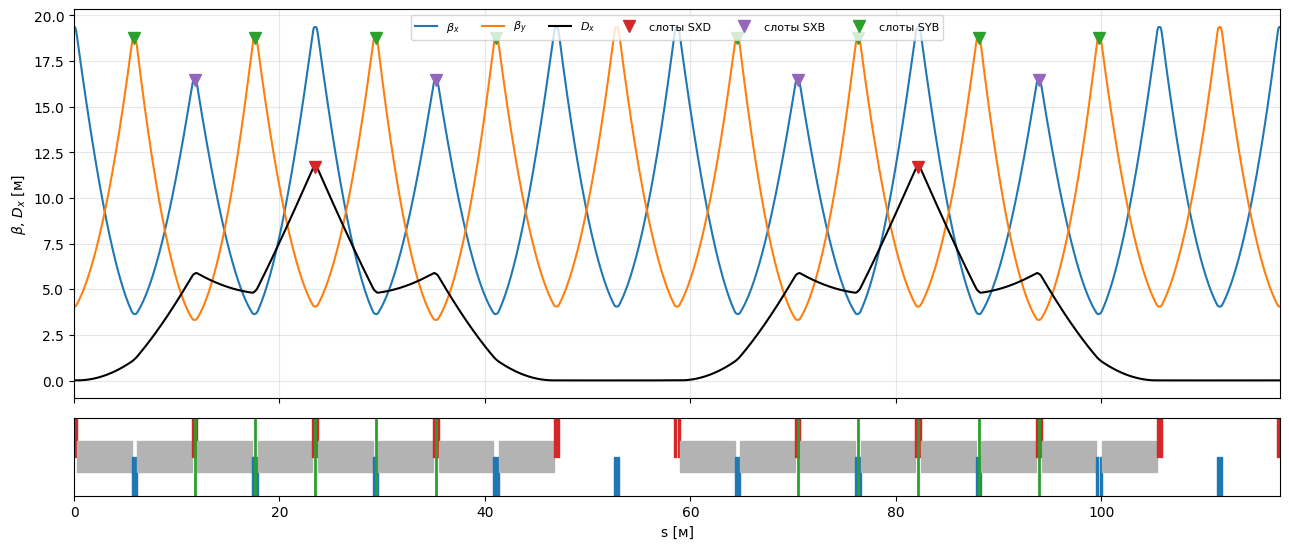

In [5]:
n2 = kv('02_numbers.csv')
display(pd.Series({k: n2[k] for k in ['C_m', 'Qx', 'Qy', 'alpha0', 'alpha1', 'eta0', 'eta1', 'gamma_t']}, name='значение').to_frame())
fig, (ax, axe) = plt.subplots(2, 1, figsize=(13, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[5, 1]))
ax.plot(opt.s_m, opt.betx_m, label=r'$\beta_x$'); ax.plot(opt.s_m, opt.bety_m, label=r'$\beta_y$'); ax.plot(opt.s_m, opt.Dx_m, 'k', label=r'$D_x$')
for (f, d), c in zip(FAM.items(), ['C3', 'C4', 'C2']):
    ax.plot(d.sc, at('Dx_m' if f == 'SXD' else 'betx_m' if f == 'SXB' else 'bety_m', d.sc), 'v', ms=9, color=c, label=f'слоты {f}')
ax.set_ylabel(r'$\beta$, $D_x$ [м]'); ax.grid(alpha=.3); ax.legend(ncol=6, fontsize=8, loc='upper center')
for _, e in seq.iterrows():
    if e.type == 'SBend': axe.axvspan(e.s0, e.s1, .3, .7, color='0.7')
    elif e.type == 'Quadrupole': axe.axvspan(e.s0, e.s1, *((.5, 1) if e.k1 > 0 else (0, .5)), color='C3' if e.k1 > 0 else 'C0')
    elif e.type == 'Sextupole': axe.axvline(e.sc, color='C2', lw=2)
axe.set_yticks([]); axe.set_xlabel('s [м]'); axe.set_xlim(0, CIRC); plt.tight_layout(); plt.show()

**Рисунок 2.** Функции $\beta_x$, $\beta_y$ и дисперсия $D_x$ вдоль кольца (шаг 0.02 м, $k_2=0$). Внизу — схема: серые — BM, красные
вверх — QF, синие вниз — QD, зелёные — секступоли. Треугольники — слоты семейств шага 5: SXD в максимуме $D_x$, SXB в максимумах
$\beta_x$, SYB в максимумах $\beta_y$.

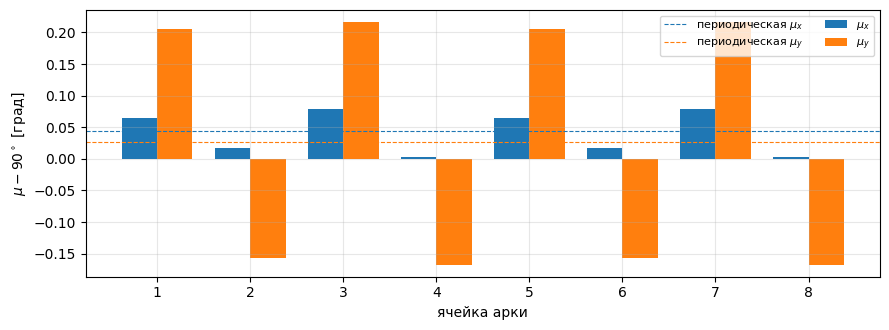

,name,harmonic,voltage_MV,delta_m,phi_s_rad,sin_phi_s,cos_phi_s,phi_hat,phi_hat_squared,Qs,...,abs_Lambda_over_eta0_delta_m,two_pi_frac_nu_x,two_pi_frac_nu_y,two_pi_nearest_nu_x,two_pi_nearest_nu_y,omega_s_Ts_over_two_pi_frac_nu_x,omega_s_Ts_over_two_pi_frac_nu_y,omega_s_Ts_over_two_pi_nearest_nu_x,omega_s_Ts_over_two_pi_nearest_nu_y,formula_delta_eq
linear,linear,1,0.00678733,0.0001,0,0,1,0.05,0.0025,0.00106738,...,9.54721e-05,2.90107,2.89867,2.90107,2.89867,0.00231174,0.00231366,0.00231174,0.00231366,1.90767e-08
cubic_phase,cubic_phase,1,0.000188537,0.0001,0,0,1,0.3,0.09,0.000177896,...,9.54721e-05,2.90107,2.89867,2.90107,2.89867,0.00038529,0.00038561,0.00038529,0.00038561,1.90499e-08


linear       φ̂ = h|η0|δm/Qs = 0.0500
cubic_phase  φ̂ = h|η0|δm/Qs = 0.3000


In [6]:
cells = pd.read_csv(OUT / '02_cells.csv'); cells = cells[cells.kind == 'arc_cell']
fig, ax = plt.subplots(figsize=(9, 3.4)); w = .38
ax.bar(cells['index'] - w / 2, cells.mu_x_deg - 90, w, label=r'$\mu_x$'); ax.bar(cells['index'] + w / 2, cells.mu_y_deg - 90, w, label=r'$\mu_y$')
ax.axhline(np.degrees(cells.mu_x_periodic_rad.iloc[0]) - 90, color='C0', ls='--', lw=.8, label=r'периодическая $\mu_x$')
ax.axhline(np.degrees(cells.mu_y_periodic_rad.iloc[0]) - 90, color='C1', ls='--', lw=.8, label=r'периодическая $\mu_y$')
ax.set_xlabel('ячейка арки'); ax.set_ylabel(r'$\mu-90^\circ$ [град]'); ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
j = json.load(open(OUT / '02_rf_regimes.json', encoding='utf-8')); reg = pd.DataFrame(j['regimes']).T
display(reg)
for name, r in j['regimes'].items():
    print(f"{name:12s} φ̂ = h|η0|δm/Qs = {1 * abs(n2['eta0']) * r['delta_m'] / r['Qs']:.4f}")

**Рисунок 3.** Набег фазы на ячейку арки в кольце минус $90^\circ$ (столбцы) и периодический набег ячейки, взятой отдельно (пунктир).

**Выводы.** Оптика симметрична: две суперпериодические копии по 42 элемента, $\beta_{max}\approx19.4$ м в обеих плоскостях,
$D_{x,max}=11.70$ м в слоте SF1. Ячейки арки — практически $90^\circ$ (разброс $0.08^\circ$ по $x$ и $0.4^\circ$ по $y$, его создают прямые
промежутки). $Q_x=2.46172$ и $Q_y=2.46134$ почти равны: $|Q_x-Q_y|=3.8\cdot10^{-4}$ — это важно для шага 7. Ниже критической энергии
$\eta_0=-0.534$, а $\eta_1=+1.017$: $\delta_{eq}$ без секступолей положителен. Матрица, фактор Ли и `path_expansion` совпадают до $10^{-8}$.
Замечание: JSON режимов хранит фазу заметок $\phi_s^N=0$, а полость в BELL на шагах 3–7 стоит на $\pi$.

## 2b. Хроматичность из генераторов Ли
Фактор одного оборота без ВЧ $\mathcal M=e^{:f_2:}e^{:f_3:}e^{:f_4:}$ переводится в нормальные координаты матрицей $A$:
симплектический дисперсионный сдвиг ($x\to x+D\delta$, $p_x\to p_x+D'\delta$, $l\to l-D'x+Dp_x$), затем нормировка Куранта–Снайдера.
В этих координатах $f_2=-\mu_xJ_x-\mu_yJ_y+\dots$, а кубический генератор содержит $c\,J\delta$. Так как поворот на $+\mu$ — это генератор $-\mu J$,
$$\mu(\delta)=\mu-c\,\delta\;\Rightarrow\;\xi_1=\frac{dQ}{d\delta}=-\frac{c}{2\pi}.$$
Второй порядок даёт член $c_2J\delta^2$ в $f_4-\tfrac12[f_3,F_3]$, где $F_3$ решает гомологическое уравнение $F_3-F_3\circ r=-f_3$:
$d^2Q/d\delta^2=-c_2/\pi$. Независимая проверка — отклик одного секступоля $\Delta\xi_{x,y}=\pm k_2L\beta_{x,y}D_x/(4\pi)$.
`symplectic_eigen_A` тут не годится: продольный блок магнитной карты — сдвиг, а не вращение (BELL issue #65).

In [7]:
run_step('02b_generator_chromaticity.jl', '02b_chromaticity.md')

# Step 2b. Chromaticity of the closed magnetic ring from the Lie generators.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/02b_generator_chromaticity.jl
#
# The one-turn factor is ring_lie_factor with no RF. The normalising matrix
# is built in src/generator_chromaticity.jl. symplectic_eigen_A is called
# once, only to record what it does with the magnetic shear. Its output is
# not a chromaticity.

RUN_JULIA не задан: показан сохранённый отчёт output/02b_chromaticity.md.


<details><summary><b>Отчёт <code>output/02b_chromaticity.md</code></b></summary>

# Chromaticity from the magnetic Lie generators

Lattice file: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Reference: deuteron, kinetic energy 270.0 MeV, harmonic 1. No RF. The bare case has every sextupole at `k2 = 0`.

The one-turn object is `ring_lie_factor` of `magnetic_lattice`. `chromaticity_orders` reads `factor_to_map` of that factor. `chromaticity_series` builds `one_turn_map_da` at order 4. The normalising matrix is not `symplectic_eigen_A`.

## Normalisation

`A` maps normal coordinates to canonical coordinates: dispersion shear, then the Courant–Snyder matrix of each plane at the ring start. The shear is `x → x + D δ`, `p_x → p_x + D' δ`, and `l → l − D' x + D p_x`, with the same pattern in `y`. Actions are `J = (q² + p²) / 2`.

| quantity | k2 = 0 | one sextupole |
| --- | --- | --- |
| symplectic error of A | 6.67123917e-21 | 6.67123917e-21 |
| symplectic error of the shear | 2.03078623e-23 | 2.03078623e-23 |
| max |R_n[1:4, δ]| | 8.67361738e-19 | 8.67361738e-19 |
| max |R_shear[1:4, δ]| | 1.73472348e-18 | 1.73472348e-18 |
| max |R_n[l, 1:4]| | 3.80121282e-15 | 3.80121282e-15 |
| rotation residual | 1.87627691e-14 | 1.87627691e-14 |
| transverse coupling of R_n | 0.00000000e+00 | 0.00000000e+00 |
| max |R_n[δ, 1:5]| | 0.00000000e+00 | 0.00000000e+00 |
| (l|δ) in normal coordinates | 6.26487986e+01 | 6.26487986e+01 |
| max |coef| of f3 monomials with l | 0.00000000e+00 | 0.00000000e+00 |
| max |coef| of f4 monomials with l | 0.00000000e+00 | 0.00000000e+00 |
| |q² − p²| coefficient, x, Jδ | 2.75731501e-01 | 1.34913220e+01 |
| |q p| coefficient, x, Jδ | 1.21341809e-02 | 3.21357783e+00 |
| |q² − p²| coefficient, y, Jδ | 2.56772944e-01 | 3.02078843e+00 |
| homological residual | 3.50015475e-15 | 3.50067197e-14 |
| max |coef| of F3 | 2.28476779e+00 | 2.91100959e+01 |
| kernel dimension | 8 | 8 |
| smallest kept singular value | 2.40537126e-03 | 2.40537126e-03 |
| |Lie R − ring_matrix| | 2.70006240e-13 | 2.70006240e-13 |
| |periodic D − dispersion_orders| | 0.00000000e+00 | 0.00000000e+00 |

Normalisation checks are within 1.0e-8: true.

## First chromaticity

The cubic generator in normal coordinates contains `c_x J_x δ + c_y J_y δ`. The map is `exp(:f:)`, and the angle that matches `rotation` by `+μ` is the generator `−μ J`. The overall factor was required to be one entry of a fixed list, the same number on both planes, and was compared with `chromaticity_orders` at step `1e-6` on the `k2 = 0` ring.

| quantity | value |
| --- | --- |
| c_x of J_x δ | 9.18309974e+00 |
| c_y of J_y δ | 1.39831342e+01 |
| ξ1_x / c_x | -1.59154943e-01 |
| ξ1_y / c_y | -1.59154943e-01 |
| candidate | -1/(2π) |
| factor | -1.59154943e-01 |
| max relative residual | 1.304e-10 |
| accepted | yes |

Accepted factor: ξ1 = -1/(2π) × (coefficient of J δ). On this factor, `d²Q/dδ²` predicted from a term `c₂ J δ²` is `2 × -1/(2π) × c₂`.

`chromaticity_orders` is a central difference. Steps `1e-4` (the default), `1e-5`, and `1e-6` are all stored. The comparison with `chromaticity_series` uses the step `1e-6` once the three steps have settled. ξ1 is `dQ/dδ`. ξ2 is `d²Q/dδ²`, the third component of `chromaticity_orders` and the second derivative from `chromaticity_series`.

## Bare ring, k2 = 0

| plane | quantity | generator | orders 1e-4 | orders 1e-6 | series |
| --- | --- | --- | --- | --- | --- |
| x | ξ1 | -1.46153572e+00 | -1.46153752e+00 | -1.46153572e+00 | -1.46153572e+00 |
| x | ξ2 | 8.55459555e+00 | 8.55473511e+00 | 8.55454596e+00 | 8.55459555e+00 |
| y | ξ1 | -2.22548493e+00 | -2.22548794e+00 | -2.22548493e+00 | -2.22548493e+00 |
| y | ξ2 | 8.10379124e+00 | 8.10412260e+00 | 8.10368439e+00 | 8.10379124e+00 |

Generator ξ2 in that table uses `c₂` from `f4 − ½[f3, F3]` and the direct prediction `2 × factor × c₂`. It is not rescaled. `F3` is the solution of `F3 − F3 ∘ r = −f3` on the non-resonant cubic. The row `ξ2 plus` below is the same prediction with the bracket added instead of subtracted.

| plane | ξ2 from f4 − ½[f3,F3] | ξ2 from f4 + ½[f3,F3] | orders 1e-6 | series |
| --- | --- | --- | --- | --- |
| x | 8.55459555e+00 | 8.45604679e+00 | 8.55454596e+00 | 8.55459555e+00 |
| y | 8.10379124e+00 | 7.97201327e+00 | 8.10368439e+00 | 8.10379124e+00 |

| plane | c₂ of f4 − ½[f3,F3] | c₂ of f4 + ½[f3,F3] | c₂ in f4 alone | |q² − p²| of the minus quartic |
| --- | --- | --- | --- | --- |
| x | -2.68750545e+01 | -2.65654545e+01 | -2.67202545e+01 | 4.47604967e+00 |
| y | -2.54588110e+01 | -2.50448183e+01 | -2.52518147e+01 | 5.64485767e+00 |

Second chromaticity: f4 − ½[f3, F3] reproduces d²Q/dδ² with the ξ1 factor, on the bare ring and with one sextupole. f4 + ½[f3, F3] is stored as xi2_plus and is not the reported value. Extra factor on top of the ξ1 conversion: 1.

## One sextupole

The slot is the existing sextupole with the largest `|β_x D_x|` at its centre. Centre values are the drift transport of the entrance Twiss across half the element. The horizontal formula is `+k2 L β_x D_x / (4π)`. The vertical formula is `−k2 L β_y D_x / (4π)`. `D_x` is the horizontal dispersion in both planes. The integral column uses `k2 ∫ β D_x ds / (4π)` with the same signs.

| quantity | value |
| --- | --- |
| element index | 59 |
| name | SF1 |
| s at entrance [m] | 8.21118072e+01 |
| L [m] | 1.20000000e-01 |
| k2 [1/m³] | 1.00000000e+00 |
| βx at centre [m] | 1.93675294e+01 |
| βy at centre [m] | 4.05447112e+00 |
| Dx at centre [m] | 1.17016103e+01 |
| formula Δξx centre | 2.16416932e+00 |
| formula Δξy centre | -4.53055310e-01 |
| formula Δξx integral | 2.16417625e+00 |
| formula Δξy integral | -4.53088382e-01 |

Other sextupoles stay at `k2 = 0`. Linear matrices of the bare and excited rings differ by 0.00000000e+00.

| plane | quantity | generator | orders 1e-4 | orders 1e-6 | series |
| --- | --- | --- | --- | --- | --- |
| x | ξ1 | 7.02640529e-01 | 7.02649751e-01 | 7.02640530e-01 | 7.02640529e-01 |
| x | ξ2 | 1.22897420e+02 | 1.22898754e+02 | 1.22897470e+02 | 1.22897420e+02 |
| y | ξ1 | -2.67857332e+00 | -2.67857656e+00 | -2.67857332e+00 | -2.67857332e+00 |
| y | ξ2 | 7.34244467e+00 | 7.34284980e+00 | 7.34229344e+00 | 7.34244467e+00 |

The same bracket test on the sextupole. The plus combination changes sign relative to `chromaticity_series`. The minus combination stays with it.

| plane | ξ2 from f4 − ½[f3,F3] | ξ2 from f4 + ½[f3,F3] | orders 1e-6 | series |
| --- | --- | --- | --- | --- |
| x | 1.22897420e+02 | -1.20506701e+02 | 1.22897470e+02 | 1.22897420e+02 |
| y | 7.34244467e+00 | -6.65847996e+00 | 7.34229344e+00 | 7.34244467e+00 |

| plane | Δξ1 generator | Δξ1 orders 1e-6 | Δξ1 series | formula centre | formula integral |
| --- | --- | --- | --- | --- | --- |
| x | 2.16417625e+00 | 2.16417625e+00 | 2.16417625e+00 | 2.16416932e+00 | 2.16417625e+00 |
| y | -4.53088382e-01 | -4.53088382e-01 | -4.53088382e-01 | -4.53055310e-01 | -4.53088382e-01 |

Sextupole survey, centre values, bare strengths:

| index | name | s0 [m] | L [m] | βx [m] | βy [m] | Dx [m] | role |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 9 | SF2 | 1.16788296e+01 | 1.20000000e-01 | 1.64584225e+01 | 3.32369705e+00 | 5.85183022e+00 |  |
| 13 | SD | 1.75482444e+01 | 1.20000000e-01 | 3.64896769e+00 | 1.87680353e+01 | 4.89102216e+00 |  |
| 17 | SF1 | 2.34176592e+01 | 1.20000000e-01 | 1.93675294e+01 | 4.05447112e+00 | 1.17016103e+01 |  |
| 21 | SD | 2.92870740e+01 | 1.20000000e-01 | 3.64896769e+00 | 1.87680353e+01 | 4.89102216e+00 |  |
| 25 | SF2 | 3.51564888e+01 | 1.20000000e-01 | 1.64584225e+01 | 3.32369705e+00 | 5.85183022e+00 |  |
| 51 | SF2 | 7.03729776e+01 | 1.20000000e-01 | 1.64584225e+01 | 3.32369705e+00 | 5.85183022e+00 |  |
| 55 | SD | 7.62423924e+01 | 1.20000000e-01 | 3.64896769e+00 | 1.87680353e+01 | 4.89102216e+00 |  |
| 59 | SF1 | 8.21118072e+01 | 1.20000000e-01 | 1.93675294e+01 | 4.05447112e+00 | 1.17016103e+01 | chosen |
| 63 | SD | 8.79812220e+01 | 1.20000000e-01 | 3.64896769e+00 | 1.87680353e+01 | 4.89102216e+00 |  |
| 67 | SF2 | 9.38506368e+01 | 1.20000000e-01 | 1.64584225e+01 | 3.32369705e+00 | 5.85183022e+00 |  |

## Agreement

On each case, `chromaticity_orders` at step `1e-6` and `chromaticity_series` agree within 0.0001 on ξ1 and within 0.001 on ξ2. `ring_matrix` and the Lie factor `R` agree within 1.0e-8, and so do `periodic_optics` dispersion and `dispersion_orders`. The finite-difference steps are printed so the truncation of the default step `1e-4` can be seen.

A generator value is this study's reading of the Lie factor. Where it disagrees with a BELL column, both numbers stay in the table.

## What symplectic_eigen_A does on this factor

Called on `F.R` of the bare ring and not used afterwards.

```
Elliptic pairs with Im λ > 1e-8: 2.
Eigenvalues: -9.712144e-01-2.382071e-01im, -9.712144e-01+2.382071e-01im, -9.706386e-01-2.405425e-01im, -9.706386e-01+2.405425e-01im, +1.000000e+00+0.000000e+00im, +1.000000e+00+0.000000e+00im.
symplectic_eigen_A: threw: one-turn matrix not stable
```


</details>

,case,plane,quantity,generator,orders_dd_1e-4,orders_dd_1e-5,orders_dd_1e-6,series,formula_centre,formula_integral
0,k2=0,x,xi1,-1.46154,-1.46154,-1.46154,-1.46154,-1.46154,NaN,NaN
1,k2=0,x,xi2,8.5546,8.55474,8.5546,8.55455,8.5546,NaN,NaN
2,k2=0,x,xi2_plus,8.45605,8.55474,8.5546,8.55455,8.5546,NaN,NaN
3,k2=0,y,xi1,-2.22548,-2.22549,-2.22548,-2.22548,-2.22548,NaN,NaN
4,k2=0,y,xi2,8.10379,8.10412,8.10379,8.10368,8.10379,NaN,NaN
5,k2=0,y,xi2_plus,7.97201,8.10412,8.10379,8.10368,8.10379,NaN,NaN
6,one_sextupole,x,xi1,0.702641,0.70265,0.702641,0.702641,0.702641,NaN,NaN
7,one_sextupole,x,xi2,122.897,122.899,122.897,122.897,122.897,NaN,NaN
8,one_sextupole,x,xi2_plus,-120.507,122.899,122.897,122.897,122.897,NaN,NaN
9,one_sextupole,y,xi1,-2.67857,-2.67858,-2.67857,-2.67857,-2.67857,NaN,NaN


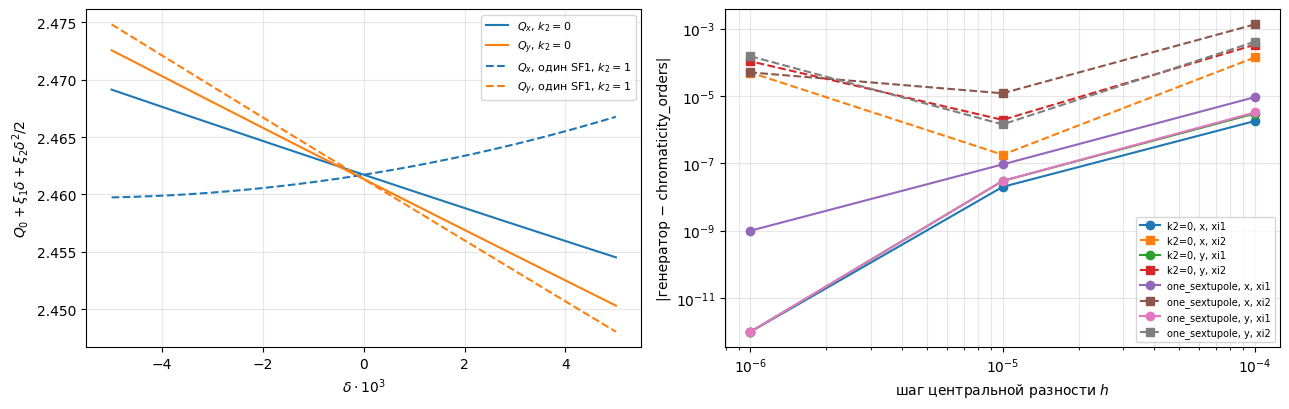

In [8]:
ch = pd.read_csv(OUT / '02b_chromaticity.csv'); display(ch)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
d = np.linspace(-5e-3, 5e-3, 201); Q0 = {'x': n2['Qx'], 'y': n2['Qy']}
for case, ls in (('k2=0', '-'), ('one_sextupole', '--')):
    for p, c in (('x', 'C0'), ('y', 'C1')):
        g = ch[(ch.case == case) & (ch.plane == p)].set_index('quantity').generator
        a1.plot(d * 1e3, Q0[p] + g.xi1 * d + g.xi2 * d**2 / 2, ls, color=c, label=f'$Q_{p}$, ' + ('$k_2=0$' if case == 'k2=0' else 'один SF1, $k_2=1$'))
a1.set_xlabel(r'$\delta\cdot10^3$'); a1.set_ylabel(r'$Q_0+\xi_1\delta+\xi_2\delta^2/2$'); a1.grid(alpha=.3); a1.legend(fontsize=8)
steps = [1e-4, 1e-5, 1e-6]
for _, r in ch[ch.quantity.isin(['xi1', 'xi2'])].iterrows():
    err = [abs(r.generator - r[f'orders_dd_{h:.0e}'.replace('e-0', 'e-')]) for h in steps]
    a2.loglog(steps, np.maximum(err, 1e-12), 'o-' if r.quantity == 'xi1' else 's--', label=f'{r.case}, {r.plane}, {r.quantity}')
a2.set_xlabel('шаг центральной разности $h$'); a2.set_ylabel('|генератор − chromaticity_orders|'); a2.grid(alpha=.3, which='both'); a2.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Рисунок 4.** Слева: $Q(\delta)$ из генераторных $\xi_1$, $\xi_2$ для голого кольца и для одного SF1 с $k_2=1$ м$^{-3}$ (линейная матрица
одна и та же). Справа: расхождение генераторного значения с центральной разностью `chromaticity_orders` в зависимости от шага.

**Выводы.** Генератор даёт $\xi_1=(-1.4615,\,-2.2255)$ и $\xi_2=(8.555,\,8.104)$, совпадая с `chromaticity_series` до всех знаков, а с
`chromaticity_orders` — с расхождением, которое для $\xi_1$ падает как $h^2$, а для $\xi_2$ минимально при $h=10^{-5}$: при меньшем шаге
вторую разность портит округление $\sim\varepsilon/h^2$. Генератор свободен от обеих ошибок; шаг по умолчанию $10^{-4}$ смещает $\xi_2$ на $\sim10^{-4}$. Отклик одного секступоля $\Delta\xi=(+2.1642,\,-0.4531)$ совпадает с $k_2\!\int\!\beta D\,ds/(4\pi)$ до $10^{-8}$.
Знак скобки $-\tfrac12[f_3,F_3]$ подтверждён: с плюсом $\xi_2$ одного секступоля меняет знак. Этот способ чтения $\xi$ используется на шагах 3–7.

## 3. Инварианты Ли: $\eta_1$, нормальная форма с полостью, действия против трека
Проверяется формула заметки для $\eta_1$ (тождество скорости $-c_2+c_1^2=(3\gamma^2-1)/(2\gamma^4)$ объясняет, почему она совпадает
с `path_expansion`). Затем к решётке добавляется одна тонкая полость (линейный режим) и строится 6D нормальная форма
`dragt_finn_nf6d` фактора `ring_lie_factor`:
$$h=-\sum_k\mu_kJ_k+\sum_{i\le j}c_{ij}J_iJ_j,\qquad \delta_{eq}=z^*_6+d\cdot J.$$
Её действия $J_x,J_y,J_s$ должны сохраняться на треке, а действие Куранта–Снайдера — нет: оно не учитывает синхротронную модуляцию
дисперсионной орбиты $D\delta(t)$. Полость уже входит в `ring_lie_factor`, поэтому `one_turn_factor_rf` на такой решётке считает её
дважды: $Q_s\to\sqrt2\,Q_s$ (BELL issue #66).

In [9]:
run_step('03_lie_invariants.jl', '03_lie_invariants.md')

# Step 3. Second-order slip and chromaticity of the magnetic Lie factor,
# then the 6D normal form of the same ring with one thin cavity.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/03_lie_invariants.jl
#
# The default track covers two synchrotron periods and stops at 2000 turns.
# A longer track is the explicit flag --turns N.

RUN_JULIA не задан: показан сохранённый отчёт output/03_lie_invariants.md.


<details><summary><b>Отчёт <code>output/03_lie_invariants.md</code></b></summary>

# Lie invariants of the closed magnetic ring

Lattice file: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Sextupoles are at `k2 = 0`. Reference: deuteron, kinetic energy 270.0 MeV, gamma 1.14395294e+00, harmonic 1.

The magnetic factor is `ring_lie_factor` of `magnetic_lattice`. Slip coefficients are `path_expansion` of `factor_to_map`. Chromaticity in the generator column is `generator_chromaticity` with the factor fixed in step 2b, `ξ1 = −c / (2π)` and `ξ2 = 2 ξ1_factor c₂`, placed next to `chromaticity_orders`.

## Slip

The note formula is `η1 = α1 − α0/γ² + (3γ² − 1)/(2γ⁴)`. `eta1 − eta1_formula` uses that expression. `path_expansion` also returns its own `eta1_formula`.

| quantity | value |
| --- | --- |
| C [m] | 1.17388296e+02 |
| gamma | 1.14395294e+00 |
| 1/gamma^2 | 7.64158910e-01 |
| alpha0 | 2.30470282e-01 |
| alpha1 | 3.39007701e-01 |
| eta0 | -5.33688628e-01 |
| eta1 | 1.01716073e+00 |
| eta1_formula | 1.01716073e+00 |
| eta1 − eta1_formula | 0.000000e+00 |
| path_expansion eta1_formula | 1.01716073e+00 |
| eta1 − path_expansion eta1_formula | 0.000000e+00 |
| note formula − path_expansion formula | 0.000000e+00 |
| (-c2 + c1^2) − (3γ²−1)/(2γ⁴) | 0.000000e+00 |
| |Lie R − ring_matrix| | 2.700062e-13 |

η1 and the note formula agree within 1.0e-8. The note formula and `path_expansion`'s `eta1_formula` agree within the same tolerance. The velocity identity `−c2 + c1² = (3γ² − 1)/(2γ⁴)` is the algebraic reason those two formulas meet.

## Chromaticity

Generator ξ1 is `−1/(2π)` times the coefficient of `J δ`. Generator ξ2 is `−1/π` times the coefficient of `J δ²` in `f4 − ½[f3, F3]`. `chromaticity_orders` is the central difference of the same magnetic map. The step `1e-6` is the settled difference. The step `1e-4` is the default of that function.

| plane | quantity | generator | orders 1e-4 | orders 1e-6 | generator − orders 1e-6 |
| --- | --- | --- | --- | --- | --- |
| x | xi1 | -1.46153572e+00 | -1.46153752e+00 | -1.46153572e+00 | 1.67234226e-10 |
| x | xi2 | 8.55459555e+00 | 8.55473511e+00 | 8.55454596e+00 | 4.95857707e-05 |
| y | xi1 | -2.22548493e+00 | -2.22548794e+00 | -2.22548493e+00 | 2.90293123e-10 |
| y | xi2 | 8.10379124e+00 | 8.10412260e+00 | 8.10368439e+00 | 1.06853598e-04 |

| plane | c of J δ | c of J δ² |
| --- | --- | --- |
| x | 9.18309974e+00 | -2.68750545e+01 |
| y | 1.39831342e+01 | -2.54588110e+01 |

Generator and `chromaticity_orders` at step `1e-6` agree within 0.0001 on ξ1 and within 0.001 on ξ2.

## Thin cavity

One thin `RFCavity` is appended to the element list. Voltage and harmonic are `regimes.linear` in `02_rf_regimes.json`. The cavity phase passed to BELL is `3.14159265e+00` rad. The regime file records the notes' stationary phase `0.00000000e+00` rad. `eta0` is negative, and `eta0 * cos(phi_s)` is positive at the BELL phase, so the smooth tune is real.

The one-turn factor used below is `ring_lie_factor` of this lattice. The cavity is already an element, so its kick is inside that product. `one_turn_factor_rf` is not called.

| quantity | value |
| --- | --- |
| h | 1 |
| V [MV] | 6.78732526e-03 |
| phi_s on the cavity [rad] | 3.14159265e+00 |
| phi_s in the regime file [rad] | 0.00000000e+00 |
| Q_s note | 1.06737726e-03 |
| Q_s smooth model at phi_s = π | 1.06737726e-03 |
| Q_s stored in the regime file | 1.06737726e-03 |
| Q_s note − regime file | 0.000000e+00 |
| Q_s note − smooth model | 0.000000e+00 |

## Two ways to attach one kick, and a second kick

`ring_lie_factor` of the lattice with the cavity is compared with `concatenate` of the magnetic factor and `dragt_finn_factor(rf_kick_taylor(...))`. A further `concatenate` of the cavity-lattice factor with that same kick is the map `one_turn_factor_rf` builds when the lattice already contains the cavity: `ring_lie_factor` includes the cavity, and the function appends `rf_kick_taylor` again. Synchrotron tunes in this section are `|μ_s| / 2π` from `symplectic_eigen_A` of those linear matrices.

| quantity | value |
| --- | --- |
| |R(cavity lattice) − R(magnetic + one kick)| | 2.842171e-14 |
| |f3| gap of that comparison | 3.907985e-14 |
| |f4| gap of that comparison | 6.661338e-14 |
| Q_s of the cavity lattice | 1.06737926e-03 |
| Q_s after a second kick | 1.50950505e-03 |
| Q_s second / Q_s one | 1.41421621e+00 |

## Normal form

`dragt_finn_nf6d` returned. `Q_s = |μ_s| / 2π`. The detuning matrix is stored as `h4 = Σ_{i≤j} c_ij J_i J_j`, with zeros below the diagonal. `μ_k(J) = μ_k − ∂h4/∂J_k`, and `∂h4/∂J_k = 2 c_kk J_k + Σ_{j≠k} c_{min,max} J_j`.

| quantity | value |
| --- | --- |
| mu_x [rad] | 2.90107326e+00 |
| mu_y [rad] | 2.89866789e+00 |
| mu_s [rad] | 6.70654166e-03 |
| Q_s | 1.06737926e-03 |
| Q_s − Q_s note | 2.000339e-09 |
| wrapped |Q_x − Q_x magnetic| | 6.452061e-13 |
| wrapped |Q_y − Q_y magnetic| | 1.110223e-15 |
| |A^-1 R A − rotation| | 4.519475e-14 |
| |A^T S A − S| | 3.591450e-15 |
| max |coef| of f3 | 7.366624e-02 |
| cubic residual after F3 | 1.776357e-15 |
| |f4 − h4| after F4 | 6.221412e-14 |
| sigma_delta per sqrt(2 Js) | 1.03465069e-02 |
| sigma_l per sqrt(2 Js) | 9.66515199e+01 |

Detuning matrix `c`, rows and columns `(x, y, s)`:

| c_i1 | c_i2 | c_i3 |
| --- | --- | --- |
| -2.32364474e+00 | -3.81134833e+00 | -4.71742246e-03 |
| 0.00000000e+00 | -3.48047667e+00 | -5.53396969e-03 |
| 0.00000000e+00 | 0.00000000e+00 | 1.12162519e-02 |

| plane | d_k |
| --- | --- |
| x | 1.46580620e-01 |
| y | 2.23198761e-01 |
| s | 2.04027704e-04 |

`d` is the normal-form coefficient in `δ_eq = z*_6 + d · J`. `z*` from this call is the origin.

## Tracking

Each magnet is `exact_track_element` with step 0.1 m. The thin cavity is `rf_kick`. The observation point is the start of the element list, which is the entrance of the one-turn map. The launch point is the periodic dispersion orbit at `δ = δ_m` plus a betatron offset. The horizontal offset is twice `|D_x δ_m|` at this location (`a_x = 2.21882208e-06` m, `a_y = 2.21882208e-06` m, `δ_m = 1.00000000e-04`). `l = 0`, so the particle starts at the momentum crest of the stationary bucket.

Normal-form actions use `u = A⁻¹ (z − z*)` and `w = Tinv(u)`, then `J_k = (w_{2k−1}² + w_{2k}²) / 2`. Courant–Snyder `J` uses the on-momentum Twiss at this location. The geometric Courant–Snyder action keeps the dispersive piece of `(x, p_x)`. The dispersion-free column subtracts `D δ` first.

1874 turns, including the launch point as turn 0. Elapsed time 46.9 s. Synchrotron periods at the normal-form Q_s: 2.000.

| action | mean | min | max | max − min | (max−min)/|mean| |
| --- | --- | --- | --- | --- | --- |
| Jx NF | 1.39216466e-13 | 1.38353798e-13 | 1.40069956e-13 | 1.71615771e-15 | 1.232726e-02 |
| Jy NF | 6.07161030e-13 | 6.07046053e-13 | 6.07341523e-13 | 2.95470436e-16 | 4.866426e-04 |
| Js NF | 4.67076657e-05 | 4.67076564e-05 | 4.67076751e-05 | 1.87153965e-11 | 4.006922e-07 |
| Jx Courant-Snyder | 1.67708748e-13 | 1.32330336e-14 | 3.99169943e-13 | 3.85936909e-13 | 2.301233e+00 |
| Jy Courant-Snyder | 6.07053494e-13 | 6.06972067e-13 | 6.07134915e-13 | 1.62847309e-16 | 2.682586e-04 |
| Jx Courant-Snyder, dispersion removed | 1.39379666e-13 | 1.23468653e-13 | 1.55794627e-13 | 3.23259738e-14 | 2.319275e-01 |
| Jy Courant-Snyder, dispersion removed | 6.07053494e-13 | 6.06972067e-13 | 6.07134915e-13 | 1.62847309e-16 | 2.682586e-04 |

Figure: `03_actions.svg`. Samples: `03_actions.csv`.


</details>

,значение
C_m,117.388
gamma,1.14395
alpha0,0.23047
alpha1,0.339008
eta0,-0.533689
eta1,1.01716
eta1_formula,1.01716
eta1_minus_eta1_formula,0
bell_eta1_formula,1.01716
eta1_minus_bell_eta1_formula,0


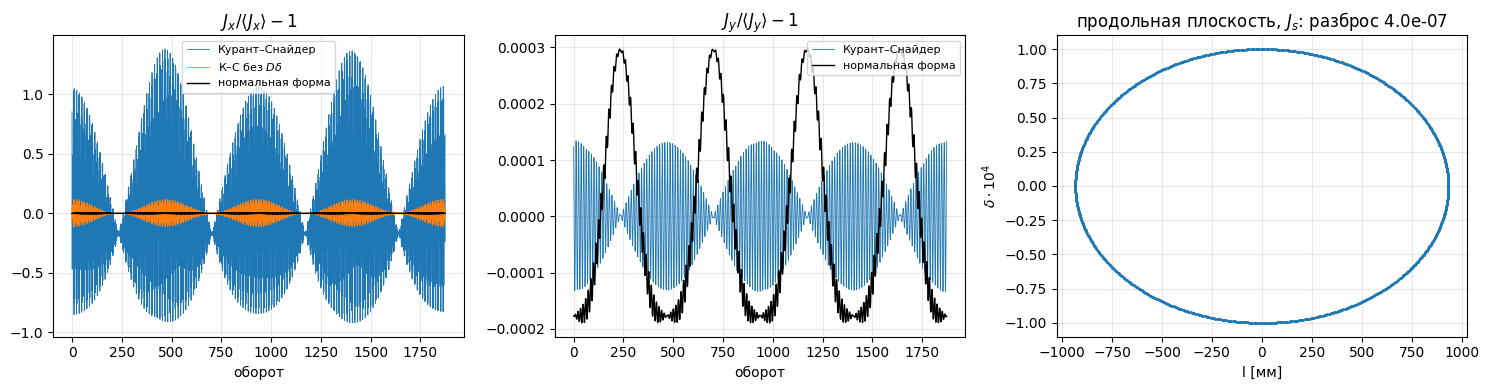

In [10]:
n3 = kv('03_numbers.csv'); display(pd.Series(n3, name='значение').to_frame())
act = pd.read_csv(OUT / '03_actions.csv'); rel = lambda c: act[c] / act[c].mean() - 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(act.turn, rel('Jx_cs'), lw=.6, label='Курант–Снайдер'); ax[0].plot(act.turn, rel('Jx_cs_dispersion_free'), lw=.6, label=r'К–С без $D\delta$')
ax[0].plot(act.turn, rel('Jx_nf'), 'k', lw=1, label='нормальная форма'); ax[0].set_title(r'$J_x/\langle J_x\rangle-1$')
ax[1].plot(act.turn, rel('Jy_cs'), lw=.6, label='Курант–Снайдер'); ax[1].plot(act.turn, rel('Jy_nf'), 'k', lw=1, label='нормальная форма')
ax[1].set_title(r'$J_y/\langle J_y\rangle-1$')
ax[2].plot(act.l * 1e3, act.delta * 1e4, '.', ms=1.5); ax[2].set_xlabel('l [мм]'); ax[2].set_ylabel(r'$\delta\cdot10^4$')
ax[2].set_title(rf"продольная плоскость, $J_s$: разброс {act.Js_nf.max() / act.Js_nf.min() - 1:.1e}")
for a in ax[:2]: a.set_xlabel('оборот'); a.legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Рисунок 5.** Трек `exact_track_element` + `rf_kick`, 1874 оборота (два синхротронных периода). Слева и в центре — относительное
изменение действий: нормальная форма (чёрный) против Куранта–Снайдера. Справа — продольный фазовый портрет.

**Выводы.** $\eta_1-\eta_1^{формула}=0$ точно, $Q_s$ нормальной формы совпадает с формулой до $2\cdot10^{-9}$. Действия нормальной формы
сохраняются: $J_x$ в пределах 1.2 %, $J_y$ — $5\cdot10^{-4}$, $J_s$ — $4\cdot10^{-7}$. Горизонтальное действие Куранта–Снайдера меняется
в 2.3 раза (вычитание $D\delta$ уменьшает это до 23 %): его искажает синхротронная модуляция дисперсионной орбиты, которую нормальная
форма с полостью учитывает. По $y$ дисперсии нет, и оба действия сохраняются на уровне $10^{-4}$; у нормальной формы $J_y$ модулирован
с синхротронным периодом (амплитуда $5\cdot10^{-4}$), у Куранта–Снайдера — биениями $2.7\cdot10^{-4}$. Это различие здесь не разбиралось. Двойной учёт полости подтверждён: $Q_s$ после второго удара в $1.41421\approx\sqrt2$ раз больше.

## 4. Равновесный импульс без секступолей (главы 1–3)
Три случая в одной решётке ($k_2=0$), четыре независимых чтения в каждом:
**формула** заметки, **тор** нормальной формы ($z^*_6+d\cdot J$), итерация **карты степени 3** фактора `ring_lie_factor` и **точный трек**.
Из трека $\delta_{eq}$ — постоянный член гармонического фита (гармоники 1–3, тюн уточняется).

- **A**: линейный режим, $J=0$ — глава 1, $\delta_{eq}=-\eta_1\delta_m^2/(2\eta_0)$.
- **B**: линейный режим, конечные $J_x,J_y$ — глава 2, добавляется $\Lambda$ от генераторной $\xi$.
- **C**: кубический режим $\hat\phi=0.3$ — глава 3: $\langle\delta^2\rangle=\tfrac{\delta_m^2}{2}(1-\hat\phi^2/32)$, $\Omega/\omega_s=1-\hat\phi^2/16$.

Тор нормальной формы — квадратичный полином по $J$, поэтому поправку $\hat\phi^2$ он не содержит и сравнивается с главами 1–2.

In [11]:
run_step('04_equilibrium.jl', '04_equilibrium.md')

# Step 4. Equilibrium momentum of the closed magnetic ring, sextupoles off.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/04_equilibrium.jl
#
# Chapters 1–3 of notes/equilibrium-energy-v3. The cavity phase stored in
# BELL is π. The notes' phase is late-positive, so φ^N = −φ^B, and below
# transition the notes' stationary phase is 0.
#
# Columns, for each case: the note formula, the normal-form torus average,
# iteration of the degree-3 map of ring_lie_factor, and exact_track_element
# with rf_kick on the thin cavity. Nothing is imported from
# Julia/equilibrium_energy. --turns N replaces the default of three
# synchrotron periods. That flag is the explicit longer or shorter run.

RUN_JULIA не задан: показан сохранённый отчёт output/04_equilibrium.md.


<details><summary><b>Отчёт <code>output/04_equilibrium.md</code></b></summary>

# Equilibrium momentum of the closed magnetic ring

## STOP

- C cubic J=0 map δ_eq is closer to chapter 1-2 than to 1 - phi_hat^2/32. measured 9.544986450512834e-9, chapter 1-2 9.529533453586332e-9, chapter 3 9.50273164074812e-9. The tune and the third harmonic of this series do carry phi_hat^2; the mean momentum does not.

Sextupoles are at `k2 = 0`. One thin cavity is appended. BELL stores `phi_s = π` because `l > 0` is an early arrival. The notes' phase is late-positive, so `φ^N = −φ^B`. Below transition the notes' stationary phase is 0, and `η0 cos φ_s^B > 0` at `φ_s^B = π`.

The normal-form torus is the average of `U6` on the action torus. It is the quadratic piece `z*_6 + d · J` (`d_grid` is the same average at action `1e-8`). That polynomial stops before `φ̂²`, so the torus is compared with chapters 1–2 even in the cubic-phase regime.

`δ_eq`, `δ_m`, and the second harmonic of a tracked series come from a harmonic least-squares fit, harmonics 1–3, with the tune refined on a grid. `δ_m` in the table is the half-range `(max − min) / 2`. The signed second harmonic is the coefficient of `cos 2ψ` after `ψ` is measured from the crest of the fundamental. `⟨δ²⟩` is `(a1² + a2² + a3²) / 2`, the average of that waveform over a full period. `γ_eff` and `ΔE/E` use that column's `δ_eq` and `⟨δ²⟩`. Agreement is judged on `δ_eq`.

## Phase dictionary

Linear-regime voltage, `J = 0`, launch at `δ = δ_m` and `l = 0`. The control uses the same voltage with `phi_s = 0`. A run that reaches `|δ| = 0.01` stops early.

| phi_s BELL | turns asked | samples | aborted | min delta | max delta | max |delta| | oscillates | left bucket |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 3.14159265e+00 | 937 | 938 | false | -9.99929508e-05 | 1.00000046e-04 | 1.00000046e-04 | true | false |
| 0.00000000e+00 | 937 | 938 | false | 1.00000000e-04 | 4.00735480e-03 | 4.00735480e-03 | false | true |

## Slip, chromaticity, inequalities

| quantity | value |
| --- | --- |
| C_m | 1.17388296e+02 |
| gamma | 1.14395294e+00 |
| beta | 4.85634729e-01 |
| eta0 | -5.33688628e-01 |
| eta1 | 1.01716073e+00 |
| xi_x_generator | -1.46153572e+00 |
| xi_y_generator | -2.22548493e+00 |
| Jx | 2.58161271e-08 |
| Jy | 2.58202566e-08 |
| Lambda | 5.09522845e-09 |
| Lambda_json_placeholder | 5.09523510e-09 |
| abs_eta1_delta_m_over_eta0 | 1.90590669e-04 |
| delta_m | 1.00000000e-04 |
| abs_Lambda_over_eta0_delta_m | 9.54719321e-05 |
| linear_phi_hat | 5.00000000e-02 |
| linear_phi_hat_squared | 2.50000000e-03 |
| linear_omega_s_Ts | 6.70652909e-03 |
| linear_omega_over_betatron_x | 2.31174069e-03 |
| linear_omega_over_betatron_y | 2.31365901e-03 |
| linear_Qs | 1.06737726e-03 |
| linear_Qs_smooth_phi_pi | 1.06737726e-03 |
| linear_voltage_MV | 6.78732526e-03 |
| cubic_phase_phi_hat | 3.00000000e-01 |
| cubic_phase_phi_hat_squared | 9.00000000e-02 |
| cubic_phase_omega_s_Ts | 1.11775485e-03 |
| cubic_phase_omega_over_betatron_x | 3.85290114e-04 |
| cubic_phase_omega_over_betatron_y | 3.85609836e-04 |
| cubic_phase_Qs | 1.77896209e-04 |
| cubic_phase_Qs_smooth_phi_pi | 1.77896209e-04 |
| cubic_phase_voltage_MV | 1.88536813e-04 |

Generator `ξ` is `−c / (2π)` for the coefficient of `J δ`. `Λ = −2π (J_x ξ_x + J_y ξ_y) / C` uses that `ξ` and the placeholder actions of `02_rf_regimes.json`.

`|η1 δ_m / η0|`, `δ_m`, `|Λ / (η0 δ_m)|`, the linear `φ̂`, the cubic `φ̂²`, and `ω_s T_s` (also divided by the betatron phase) are much less than 1. The cubic `φ̂` is not required to be much less than 1.

## A linear J=0

Linear voltage, `J_x = J_y = 0`. The formula is chapter 1: `⟨δ²⟩ = δ_m²/2`, `Λ = 0`.

| target | value |
| --- | --- |
| delta_eq chapter 1-2 | 9.52953345e-09 |
| delta_eq chapter 3 | 9.52878896e-09 |
| delta_eq full pendulum | 9.52878888e-09 |
| second harmonic cos 2psi | -5.72370752e-09 |
| Omega/omega_s chapter 3 | 0.99984375 |
| Omega/omega_s pendulum | 0.99984375 |
| Lambda | 0.00000000e+00 |

NF `d · J` = 9.52953345e-09, `d_grid · J` = 9.52953345e-09, torus mean = 9.52953345e-09. `J_s` = 4.67070563e-05 from `δ_m² / (2 σ_δ²)` with `σ_δ` = 1.03465069e-02.

| quantity | formula | NF torus | degree-3 map | exact track |
| --- | --- | --- | --- | --- |
| delta_eq | 9.52953345e-09 | 9.52953345e-09 | 9.52935139e-09 | 9.52817969e-09 |
| delta_m half-range | 1.00000000e-04 | 9.99955318e-05 | 9.99965405e-05 | 9.99965410e-05 |
| second harmonic cos 2psi | -5.72370752e-09 | -5.72376469e-09 | -5.72338773e-09 | -5.72180968e-09 |
| second harmonic amplitude | 5.72370752e-09 | 5.72376469e-09 | 5.72338773e-09 | 5.72180968e-09 |
| Q / Q_note | 1.00000000 | 1.00000187 | 0.99984558 | 0.99984539 |
| mean square of delta | 5.00000000e-09 | 4.99921881e-09 | 4.99928487e-09 | 4.99928493e-09 |
| phi_hat | 5.00000000e-02 | nan | 5.00035181e-02 | 5.00035074e-02 |
| gamma_eff | 1.14395294e+00 | 1.14395294e+00 | 1.14395294e+00 | 1.14395294e+00 |
| Delta E / E | 2.69800573e-09 | 2.69793534e-09 | 2.69789835e-09 | 2.69762202e-09 |

Map residual rms 3.24059766e-13, exact residual rms 6.08084243e-13. Map `δ_eq` split 6.37737359e-17, exact split 6.82055006e-16. Turns: map 2811, exact 2811. Degree-3 image of the origin, delta component 0.00000000e+00.

## B linear finite J

Same linear voltage. `J_x` and `J_y` are the placeholder actions. `Λ` uses generator chromaticity.

| target | value |
| --- | --- |
| delta_eq chapter 1-2 | 1.90767267e-08 |
| delta_eq chapter 3 | 1.90759822e-08 |
| delta_eq full pendulum | 1.90759821e-08 |
| second harmonic cos 2psi | -5.72370752e-09 |
| Omega/omega_s chapter 3 | 0.99984375 |
| Omega/omega_s pendulum | 0.99984375 |
| Lambda | 5.09522845e-09 |

NF `d · J` = 1.90767267e-08, `d_grid · J` = 1.90767267e-08, torus mean = 1.90767267e-08. `J_s` = 4.67070563e-05 from `δ_m² / (2 σ_δ²)` with `σ_δ` = 1.03465069e-02.

| quantity | formula | NF torus | degree-3 map | exact track |
| --- | --- | --- | --- | --- |
| delta_eq | 1.90767267e-08 | 1.90767267e-08 | 1.90752571e-08 | 1.90740626e-08 |
| delta_m half-range | 1.00000000e-04 | 9.99955313e-05 | 9.99869934e-05 | 9.99869940e-05 |
| second harmonic cos 2psi | -5.72370752e-09 | -5.72376469e-09 | -5.72229984e-09 | -5.72072182e-09 |
| second harmonic amplitude | 5.72370752e-09 | 5.72376469e-09 | 5.72229984e-09 | 5.72072182e-09 |
| Q / Q_note | 1.00000000 | 1.00000187 | 0.99984561 | 0.99984542 |
| mean square of delta | 5.00000000e-09 | 4.99921876e-09 | 4.99833040e-09 | 4.99833046e-09 |
| phi_hat | 5.00000000e-02 | nan | 4.99987657e-02 | 4.99987548e-02 |
| gamma_eff | 1.14395295e+00 | 1.14395295e+00 | 1.14395295e+00 | 1.14395295e+00 |
| Delta E / E | 4.94962618e-09 | 4.94955579e-09 | 4.94912916e-09 | 4.94884745e-09 |

Map residual rms 3.83111088e-13, exact residual rms 6.40989748e-13. Map `δ_eq` split 1.39377800e-15, exact split 2.35009032e-15. Turns: map 2811, exact 2811. Degree-3 image of the origin, delta component 0.00000000e+00.

## C cubic J=0

Cubic-phase voltage, `J = 0`. The formula column uses `⟨δ²⟩ = (δ_m²/2) (1 − φ̂²/32)` and `Ω/ω_s = 1 − φ̂²/16`. The torus is still the chapter 1–2 value. The pendulum column is the full sine, kept as the size of the dropped `φ^5` term.

| target | value |
| --- | --- |
| delta_eq chapter 1-2 | 9.52953345e-09 |
| delta_eq chapter 3 | 9.50273164e-09 |
| delta_eq full pendulum | 9.50263071e-09 |
| second harmonic cos 2psi | -5.72370752e-09 |
| Omega/omega_s chapter 3 | 0.99437500 |
| Omega/omega_s pendulum | 0.99437761 |
| Lambda | 0.00000000e+00 |

NF `d · J` = 9.52953345e-09, `d_grid · J` = 9.52953345e-09, torus mean = 9.52953345e-09. `J_s` = 2.80243870e-04 from `δ_m² / (2 σ_δ²)` with `σ_δ` = 4.22393223e-03.

| quantity | formula | NF torus | degree-3 map | exact track |
| --- | --- | --- | --- | --- |
| delta_eq | 9.50273164e-09 | 9.52953345e-09 | 9.54498645e-09 | 9.50125284e-09 |
| delta_m half-range | 1.00000000e-04 | 9.98593597e-05 | 9.99962098e-05 | 9.99962094e-05 |
| second harmonic cos 2psi | -5.72370752e-09 | -5.72370911e-09 | -5.72461929e-09 | -5.66769227e-09 |
| second harmonic amplitude | 5.72370752e-09 | 5.72370911e-09 | 5.72461929e-09 | 5.66769228e-09 |
| Q / Q_note | 0.99437500 | 1.00000005 | 0.99431377 | 0.99433522 |
| mean square of delta | 4.98593750e-09 | 4.97192446e-09 | 4.98532739e-09 | 4.98539996e-09 |
| phi_hat | 3.00000000e-01 | nan | 3.01128529e-01 | 3.01124980e-01 |
| gamma_eff | 1.14395294e+00 | 1.14395294e+00 | 1.14395294e+00 | 1.14395294e+00 |
| Delta E / E | 2.69041759e-09 | 2.69547584e-09 | 2.70032803e-09 | 2.69002039e-09 |

Map residual rms 8.12597653e-11, exact residual rms 1.44502925e-10. Map `δ_eq` split 1.36776944e-12, exact split 2.42291458e-12. Turns: map 16864, exact 16864. Degree-3 image of the origin, delta component 0.00000000e+00.

The run stopped on a physical disagreement. Numbers were not adjusted.


</details>

column                               formula          nf         map  \
case              quantity                                             
A linear J=0      Q               0.00106738  0.00106738  0.00106721   
                  delta2               5e-09 4.99922e-09 4.99928e-09   
                  delta_E_over_E 2.69801e-09 2.69794e-09  2.6979e-09   
                  delta_eq       9.52953e-09 9.52953e-09 9.52935e-09   
                  gamma_eff          1.14395     1.14395     1.14395   
                  unc_delta_eq             0 4.21366e-21 6.37737e-17   
B linear finite J Q               0.00106738  0.00106738  0.00106721   
                  delta2               5e-09 4.99922e-09 4.99833e-09   
                  delta_E_over_E 4.94963e-09 4.94956e-09 4.94913e-09   
                  delta_eq       1.90767e-08 1.90767e-08 1.90753e-08   
                  gamma_eff          1.14395     1.14395     1.14395   
                  unc_delta_eq             0 8.66885e-22 1.39378e-15   
C cubic J=0       Q              0.000176896 0.000177896 0.000176885   
                  delta2         4.98594e-09 4.97192e-09 4.98533e-09   
                  delta_E_over_E 2.69042e-09 2.69548e-09 2.70033e-09   
                  delta_eq       9.50273e-09 9.52953e-09 9.54499e-09   
                  gamma_eff          1.14395     1.14395     1.14395   
                  unc_delta_eq             0 5.24929e-21 1.36777e-12   

column                                 exact  
case              quantity                    
A linear J=0      Q               0.00106721  
                  delta2         4.99928e-09  
                  delta_E_over_E 2.69762e-09  
                  delta_eq       9.52818e-09  
                  gamma_eff          1.14395  
                  unc_delta_eq   6.82055e-16  
B linear finite J Q               0.00106721  
                  delta2         4.99833e-09  
                  delta_E_over_E 4.94885e-09  
                  delta_eq       1.90741e-08  
                  gamma_eff          1.14395  
                  unc_delta_eq   2.35009e-15  
C cubic J=0       Q              0.000176888  
                  delta2          4.9854e-09  
                  delta_E_over_E 2.69002e-09  
                  delta_eq       9.50125e-09  
                  gamma_eff          1.14395  
                  unc_delta_eq   2.42291e-12

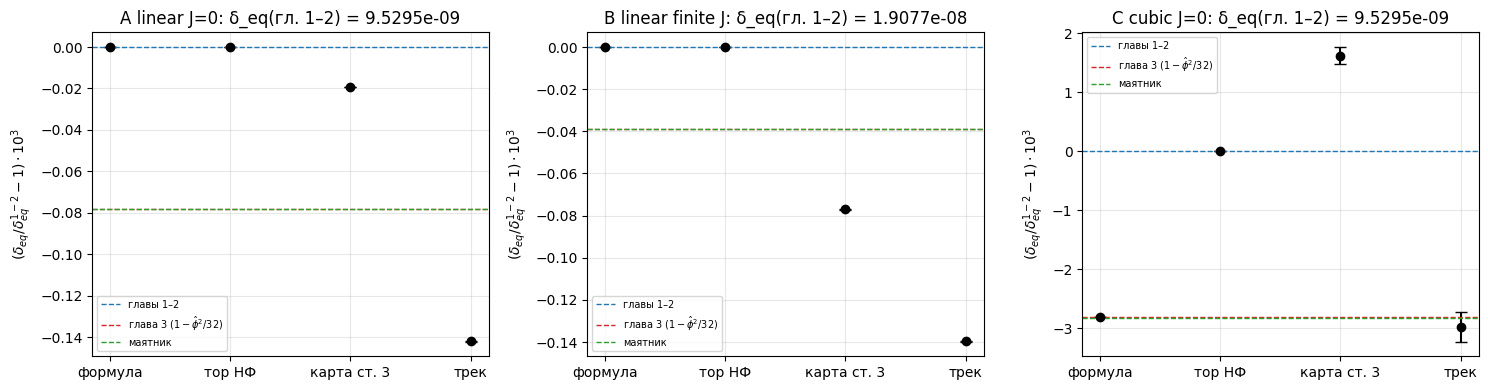

In [12]:
n4 = pd.read_csv(OUT / '04_numbers.csv')
cols = ['formula', 'nf', 'map', 'exact']
tab = n4[n4.column.isin(cols) & n4.quantity.isin(['delta_eq', 'unc_delta_eq', 'delta2', 'Q', 'gamma_eff', 'delta_E_over_E'])]
display(tab.pivot_table(index=['case', 'quantity'], columns='column', values='value')[cols])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (case, g) in zip(ax, n4.groupby('case')):
    v = g.set_index(['column', 'quantity']).value; ref = v['target', 'delta_eq_ch12']
    y = [(v[c, 'delta_eq'] / ref - 1) * 1e3 for c in cols]; e = [v[c, 'unc_delta_eq'] / ref * 1e3 for c in cols]
    a.errorbar(range(4), y, e, fmt='o', capsize=4, color='k')
    for t, c, lab in (('delta_eq_ch12', 'C0', 'главы 1–2'), ('delta_eq_ch3', 'C3', r'глава 3 ($1-\hat\phi^2/32$)'), ('delta_eq_pendulum', 'C2', 'маятник')):
        a.axhline((v['target', t] / ref - 1) * 1e3, color=c, ls='--', lw=1, label=lab)
    a.set_xticks(range(4), ['формула', 'тор НФ', 'карта ст. 3', 'трек']); a.set_title(f'{case}: δ_eq(гл. 1–2) = {ref:.4e}')
    a.set_ylabel(r'$(\delta_{eq}/\delta_{eq}^{1-2}-1)\cdot10^3$'); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Рисунок 6.** $\delta_{eq}$ в четырёх чтениях относительно значения глав 1–2 (в промилле), с погрешностью фита. Линии — значения формул.

**Выводы.**
- **A и B.** Все четыре чтения совпадают в пределах $1.5\cdot10^{-4}$ относительно: $\delta_{eq}=9.53\cdot10^{-9}$ при $J=0$ и
  $1.908\cdot10^{-8}$ при конечных $J$. Вклад $\Lambda=5.1\cdot10^{-9}$ (хроматичность × бетатронное действие) удваивает сдвиг —
  при этих действиях он сравним с синхротронным членом $\eta_1\langle\delta^2\rangle$.
- **C.** Трек ($9.5013\cdot10^{-9}$) подтверждает главу 3 ($9.5027\cdot10^{-9}$) в пределах погрешности фита и отличается от глав 1–2
  на $-3\cdot10^{-3}$, т. е. на $\hat\phi^2/32$. Тюн $\Omega/\omega_s$ из карты и трека тоже следует $1-\hat\phi^2/16$.
- **STOP скрипта** — карта степени 3 даёт $9.545\cdot10^{-9}$, ближе к главам 1–2, чем к главе 3. Это усечение: поправка $\hat\phi^2$ к
  среднему приходит из члена $\phi^4$ гамильтониана полости, которого нет в карте степени 3. Тюн и третья гармоника $\hat\phi^2$
  несут, среднее — нет. Принято как свойство усечения, числа не правились.
- $\Delta E/E\approx2.7\cdot10^{-9}$ (A) и $4.9\cdot10^{-9}$ (B); $\gamma_{eff}-\gamma\sim10^{-8}$.

## 5. Семейства секступолей: $\xi_x=\xi_y=\eta_1=0$
Три семейства по картине `place_sextupole_families`: SXD — в максимуме $D_x$ (2 магнита в SF1), SXB — в максимумах $\beta_x$ (4 в SF2),
SYB — в максимумах $\beta_y$ (8: SD и короткие дрейфы OS1 арок). В приближении тонкого магнита
$$\Delta\xi_x=\frac{1}{4\pi}\sum k_2L\beta_xD_x,\qquad \Delta\xi_y=-\frac{1}{4\pi}\sum k_2L\beta_yD_x,\qquad
\Delta\alpha_1=\Delta\eta_1=-\frac{1}{2C}\sum k_2LD_x^3 .$$
$\alpha_0$ секступоли не меняют, поэтому $\eta_1$ обнуляется через $\alpha_1=\alpha_0/\gamma^2-(3\gamma^2-1)/(2\gamma^4)=-0.678$.
Свой отклик (генераторная $\xi$ + `path_expansion`) решается на $\xi=\eta_1=0$. Сосед — `solve_A`: он обнуляет $\alpha_1$, а не $\eta_1$.

In [13]:
run_step('05_sextupoles.jl', '05_sextupoles.md')

# Step 5. Sextupole families on the closed magnetic ring.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/05_sextupoles.jl
#
# Place SXD, SXB, and SYB with place_sextupole_families. The in-study
# response is a central difference of generator chromaticity and of η1 from
# path_expansion of the magnetic factor. Its solution targets ξx = ξy = η1 = 0.
# solve_A is the neighbour: ξx = ξy = α1 = 0 from ring_metrics. Both settings,
# and k2 = 0, are read in the linear regime of output/02_rf_regimes.json.
# The cavity phase stored in BELL is π. --turns N replaces the short track.

RUN_JULIA не задан: показан сохранённый отчёт output/05_sextupoles.md.


<details><summary><b>Отчёт <code>output/05_sextupoles.md</code></b></summary>

# Sextupole families

Lattice file: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Reference: deuteron, kinetic energy 270.0 MeV, harmonic 1. Placement uses `optics_along` at ds = 0.02 m and `place_sextupole_families`. Sextupoles in the closed file are at `k2 = 0`.

Chromaticity in the in-study matrix is `generator_chromaticity` with the step-2b factor `ξ = −c / (2π)`. `η1` and `α1` are `path_expansion` of `factor_to_map` of `ring_lie_factor` on `magnetic_lattice`. The neighbour cancels `ξx`, `ξy`, and `α1` with `response` and `solve_A`. The finite-difference step is dk = 1.0 for both matrices.

## Slots

Each row is one magnet. `beta_x`, `beta_y`, and `D` are the values at the optics maximum that claimed the slot. The slot is the nearest sextupole or short drift.

| family | quantity | s_max [m] | slot | s_slot [m] | beta_x [m] | beta_y [m] | D [m] | nearest quad |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SXD | D_x | 2.34176592e+01 | SF1 | 2.34776592e+01 | 1.93677152e+01 | 4.05535903e+00 | 1.17016103e+01 | QF (F) |
| SXD | D_x | 8.22318072e+01 | SF1 | 8.21718072e+01 | 1.93677152e+01 | 4.05535903e+00 | 1.17016103e+01 | QF (F) |
| SXB | beta_x | 1.16788296e+01 | SF2 | 1.17388296e+01 | 1.64586564e+01 | 3.32479147e+00 | 5.83218650e+00 | QF (F) |
| SXB | beta_x | 3.51564888e+01 | SF2 | 3.52164888e+01 | 1.64586262e+01 | 3.32476890e+00 | 5.87147395e+00 | QF (F) |
| SXB | beta_x | 7.03729776e+01 | SF2 | 7.04329776e+01 | 1.64586564e+01 | 3.32479147e+00 | 5.83218650e+00 | QF (F) |
| SXB | beta_x | 9.38506368e+01 | SF2 | 9.39106368e+01 | 1.64586262e+01 | 3.32476890e+00 | 5.87147395e+00 | QF (F) |
| SYB | beta_y | 5.80941480e+00 | OS1 | 5.86941480e+00 | 3.66065321e+00 | 1.87836872e+01 | 1.12776958e+00 | QD (D) |
| SYB | beta_y | 1.76682444e+01 | SD | 1.76082444e+01 | 3.65973724e+00 | 1.87801732e+01 | 4.92180878e+00 | QD (D) |
| SYB | beta_y | 2.92870740e+01 | SD | 2.93470740e+01 | 3.65973724e+00 | 1.87801732e+01 | 4.92180878e+00 | QD (D) |
| SYB | beta_y | 4.11459036e+01 | OS1 | 4.10859036e+01 | 3.66065321e+00 | 1.87836872e+01 | 1.12776958e+00 | QD (D) |
| SYB | beta_y | 6.45035628e+01 | OS1 | 6.45635628e+01 | 3.66065321e+00 | 1.87836872e+01 | 1.12776958e+00 | QD (D) |
| SYB | beta_y | 7.63623924e+01 | SD | 7.63023924e+01 | 3.65973724e+00 | 1.87801732e+01 | 4.92180878e+00 | QD (D) |
| SYB | beta_y | 8.79812220e+01 | SD | 8.80412220e+01 | 3.65973724e+00 | 1.87801732e+01 | 4.92180878e+00 | QD (D) |
| SYB | beta_y | 9.98400516e+01 | OS1 | 9.97800516e+01 | 3.66065321e+00 | 1.87836872e+01 | 1.12776958e+00 | QD (D) |

Notes from `place_sextupole_families`:

- beta_x max at s=23.418 m shares slot SF1 with family SXD
- beta_x max at s=82.112 m shares slot SF1 with family SXD

Family SXD: 2 magnets, L = 0.12 m.
Family SXB: 4 magnets, L = 0.12 m.
Family SYB: 8 magnets, L = 0.12 m.

## Picture

The placement picture is SXD at a dispersion maximum, SXB near a horizontal beta maximum, and SYB near a vertical beta maximum.

SXD has 2 magnets, at the kept dispersion maximum (placed 11.7016, highest kept 11.7016). Nearest quadrupoles are focusing (QF).

SXD keeps the slot that a horizontal beta peak also asked for.

SXB has 4 magnets, below the highest kept horizontal beta maximum (placed 16.4587, highest kept 19.3677). Nearest quadrupoles are focusing (QF). The higher horizontal peaks share their slot with SXD, so this family takes the remaining horizontal peaks.

SYB has 8 magnets, at the kept vertical beta maximum (placed 18.7837, highest kept 18.7837). Nearest quadrupoles are defocusing (QD).

The largest `beta_x` sample is at s = 5.87541480e+01 m, beta_x = 1.93677385e+01 m, D = 1.10637404e-02 m. `find_optics_maxima` keeps a horizontal peak within 0.3 m of it: false. The largest `beta_y` sample is at s = 1.11458881e+02 m, D = 6.77386256e-03 m, kept: false. The largest dispersion sample is at s = 8.22318072e+01 m, D = 1.17016103e+01 m.

`find_optics_maxima` keeps a local maximum only where D > 0.5 m, including the beta curves. A horizontal peak that falls in a slot already given to SXD is omitted and printed as a shared-slot note.

## Own response

Columns are family strengths in 1/m³. Rows are dξx/dk2, dξy/dk2, and dη1/dk2. Bare readings at k2 = 0: ξx = -1.46153572e+00, ξy = -2.22548493e+00, η1 = 1.01716073e+00, α1 = 3.39007701e-01, α0 = 2.30470282e-01.

| row | SXD | SXB | SYB |
| --- | --- | --- | --- |
| dξx/dk2 | 4.32835249e+00 | 3.67885967e+00 | 8.43302449e-01 |
| dξy/dk2 | -9.06176765e-01 | -7.43004929e-01 | -4.33699520e+00 |
| dη1/dk2 | -1.63792247e+00 | -4.09700496e-01 | -2.42403976e-01 |

Condition number cond(A) = 8.84452055e+00. Rank = 3. Square = true.

The α1 that sets η1 to zero is α0/γ² − (3γ² − 1)/(2γ⁴) = -6.78153026e-01. γ = 1.14395294e+00.

Achieved after applying the own solution: α1 = -6.78153026e-01, η1 = -7.77156117e-16, ξx = 3.00385720e-16, ξy = 8.01764826e-16. α1 − target = -8.88178420e-16. Residual max(|ξx|, |ξy|, |η1|) = 8.01764826e-16.

Strengths k2 [1/m³]:

| family | own linear | own used | solve_A |
| --- | --- | --- | --- |
| SXD | 8.17687255e-01 | 8.17687255e-01 | 2.30414107e-01 |
| SXB | -4.24654677e-01 | -4.24654677e-01 | 2.65267228e-01 |
| SYB | -6.11237385e-01 | -6.11237385e-01 | -6.06726257e-01 |

NelderMead did not run. All three families are present and the re-evaluated residual is at most 0.001.

## Neighbour, solve_A

`solve_A` cancels ξx, ξy, and α1 using `ring_metrics` (`chromaticity_orders` and `path_expansion`). It does not target η1.

| family | dξx/dk2 | dξy/dk2 | dα1/dk2 | dη1/dk2 |
| --- | --- | --- | --- | --- |
| SXD | 4.32833403e+00 | -9.06177393e-01 | -1.63792247e+00 | -1.63792247e+00 |
| SXB | 3.67886770e+00 | -7.43005237e-01 | -4.09700496e-01 | -4.09700496e-01 |
| SYB | 8.43304089e-01 | -4.33701180e+00 | -2.42403976e-01 | -2.42403976e-01 |

At the `solve_A` strengths, `ring_metrics` reads ξx = 4.91867769e-06, ξy = -6.83152590e-06, α1 = -2.77555756e-16, η1 = 6.78153026e-01, η0 = -5.33688628e-01. Leftover η1 is the slip that remains when α1 is removed and the kinematic piece (3γ² − 1)/(2γ⁴) − α0/γ² is left. Formula δ_eq from these BELL readings, with Λ from the same ξ and the regime actions, is 6.35345704e-09.

The study reading of that same lattice is in the table below. |η1_study − η1_bell| = 0.00000000e+00. |ξx_study − ξx_bell| = 4.45244219e-09.

## Linear-regime equilibrium

Regime file `output/02_rf_regimes.json`, object `linear`. Voltage 0.00678732526132278 MV, harmonic 1, δ_m = 0.0001, Q_s = 0.001067377255883277, φ̂ = 0.05000000000000002. The notes' stationary phase in that file is 0.0. The cavity in the track is at BELL phase π. Actions are the placeholder Jx = 2.581612713258228e-8, Jy = 2.5820256644667e-8. Λ = −(2π/C) (Jx ξx + Jy ξy) uses the ξ of that setting. The formula is δ_eq = −(η1 δ_m²/2 + Λ) / η0. γ_eff = γ + β² γ δ_eq + β² ⟨δ²⟩ / (2γ), with ⟨δ²⟩ = δ_m²/2 in the formula and the harmonic mean square in the track.

The exact column is `exact_track_element` on the magnets and `rf_kick` on one thin cavity, ds = 0.1 m, 937 turns. δ_eq is the constant term of a harmonic fit. The tune starts at the regime Q_s and is refined on the residual, so a fraction of a turn of phase error does not leak into the constant.

| setting | ξx | ξy | η1 | α1 | Λ | formula δ_eq | exact δ_eq | formula γ_eff | exact γ_eff |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| k2=0 | -1.46153572e+00 | -2.22548493e+00 | 1.01716073e+00 | 3.39007701e-01 | 5.09522845e-09 | 1.90767267e-08 | 1.90710469e-08 | 1.14395295e+00 | 1.14395295e+00 |
| own | 3.00385720e-16 | 8.01764826e-16 | -7.77156117e-16 | -6.78153026e-01 | -1.52313225e-24 | -1.01349599e-23 | -7.13955154e-13 | 1.14395294e+00 | 1.14395294e+00 |
| solve_A | 4.92313013e-06 | -6.83486651e-06 | 6.78153026e-01 | -2.77555756e-16 | 2.64315396e-15 | 6.35345704e-09 | 6.35055992e-09 | 1.14395294e+00 | 1.14395294e+00 |

No stop. Formula and exact δ_eq agree within the step-4 tolerance, and η1 agrees with the slip identity.

Strengths for the later steps are in `output/05_sext_strengths.json`. The primary vector is `own`: ξx = ξy = η1 = 0. Rebuild by calling `place_sextupole_families` on `optics_along` of the closed lattice at ds = 0.02 m, then `set_family_strengths`.


</details>

отклик BELL/генератор                     тонкая формула            \
source                     SXD       SXB       SYB            SXD       SXB   
quantity                                                                      
dxi_x                  4.32835   3.67886  0.843302        4.32834   3.67884   
dxi_y                -0.906177 -0.743005    -4.337      -0.906111 -0.742924   
deta1                 -1.63792   -0.4097 -0.242404       -1.63792 -0.409696   

                   отношение                  
source         SYB       SXD     SXB     SYB  
quantity                                      
dxi_x     0.843226         1       1 1.00009  
dxi_y     -4.33698   1.00007 1.00011       1  
deta1    -0.242392         1 1.00001 1.00005

setting,k2=0,solve_A,own
quantity,,,
k2_SXD,0,0.230414,0.817687
k2_SXB,0,0.265267,-0.424655
k2_SYB,0,-0.606726,-0.611237
xi_x,-1.46154,4.92313e-06,3.00386e-16
xi_y,-2.22548,-6.83487e-06,8.01765e-16
alpha1,0.339008,-2.77556e-16,-0.678153
eta1,1.01716,0.678153,-7.77156e-16
Lambda,5.09523e-09,2.64315e-15,-1.52313e-24
formula_delta_eq,1.90767e-08,6.35346e-09,-1.0135e-23


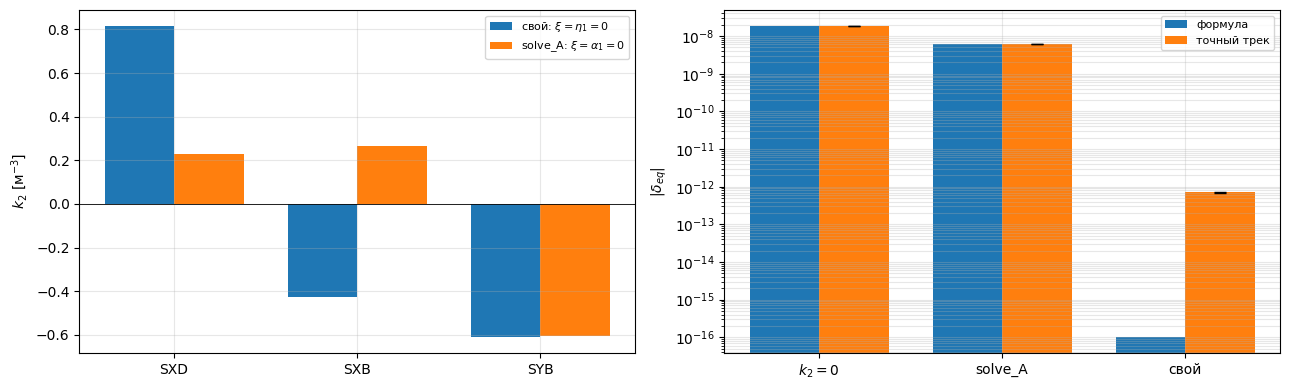

In [14]:
n5 = pd.read_csv(OUT / '05_numbers.csv')
resp = n5[n5.setting == 'response'].pivot(index='quantity', columns='source', values='value').loc[['dxi_x', 'dxi_y', 'deta1'], ['SXD', 'SXB', 'SYB']]
L = 0.12; thin = pd.DataFrame({f: [(L * at('betx_m', d.sc) * at('Dx_m', d.sc)).sum() / (4 * np.pi),
                                   -(L * at('bety_m', d.sc) * at('Dx_m', d.sc)).sum() / (4 * np.pi),
                                   -(L * at('Dx_m', d.sc)**3).sum() / (2 * CIRC)] for f, d in FAM.items()}, index=resp.index)
display(pd.concat({'отклик BELL/генератор': resp, 'тонкая формула': thin, 'отношение': resp / thin}, axis=1))
sr = n5[n5.source == 'study_reading'].pivot(index='quantity', columns='setting', values='value')[['k2=0', 'solve_A', 'own']]
display(sr.loc[['k2_SXD', 'k2_SXB', 'k2_SYB', 'xi_x', 'xi_y', 'alpha1', 'eta1', 'Lambda', 'formula_delta_eq', 'exact_delta_eq', 'exact_unc_delta_eq']])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4)); w = .38; x = np.arange(3)
a1.bar(x - w / 2, sr.loc[['k2_SXD', 'k2_SXB', 'k2_SYB'], 'own'], w, label=r'свой: $\xi=\eta_1=0$')
a1.bar(x + w / 2, sr.loc[['k2_SXD', 'k2_SXB', 'k2_SYB'], 'solve_A'], w, label=r'solve_A: $\xi=\alpha_1=0$')
a1.set_xticks(x, ['SXD', 'SXB', 'SYB']); a1.set_ylabel(r'$k_2$ [м$^{-3}$]'); a1.axhline(0, color='k', lw=.6); a1.grid(alpha=.3); a1.legend(fontsize=8)
S = ['k2=0', 'solve_A', 'own']
a2.bar(x - w / 2, np.abs(sr.loc['formula_delta_eq', S]).clip(1e-16), w, label='формула')
a2.bar(x + w / 2, np.abs(sr.loc['exact_delta_eq', S]), w, yerr=sr.loc['exact_unc_delta_eq', S], capsize=4, label='точный трек')
a2.set_yscale('log'); a2.set_xticks(x, [r'$k_2=0$', 'solve_A', 'свой']); a2.set_ylabel(r'$|\delta_{eq}|$'); a2.grid(alpha=.3, which='both'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Рисунок 7.** Слева: силы семейств для своего решения и для `solve_A`. Справа: $|\delta_{eq}|$ в линейном режиме при конечных $J$
для трёх настроек (формула — нижняя граница $10^{-16}$ для визуализации нуля).

**Выводы.**
- Отклик BELL совпадает с тонкой формулой (отношение ≈ 1 с точностью до толщины 0.12 м и до интерполяции $\beta$, $D$ в центре слота);
  в частности $\Delta\eta_1=-\sum k_2LD^3/(2C)$ — поэтому SXD в максимуме дисперсии главный рычаг по $\eta_1$. Обусловленность 8.8.
- Своё решение: $k_2=(0.818,\,-0.425,\,-0.611)$ м$^{-3}$, $\xi_x=\xi_y=\eta_1=0$ до $10^{-15}$, $\alpha_1=-0.678$. Формула даёт
  $\delta_{eq}=0$; трек — $-7.1\cdot10^{-13}\pm1.8\cdot10^{-14}$, т. е. в $2.7\cdot10^4$ раз меньше голого кольца ($1.91\cdot10^{-8}$).
  Остаток статистически значим и главами 1–3 не описывается; это порог следующего порядка, а не расхождение двух чтений одной величины.
- `solve_A` убирает $\alpha_1$, но оставляет кинематический $\eta_1=0.678$ и $\delta_{eq}=6.35\cdot10^{-9}$ (формула и трек совпадают).
  Для задачи равновесной энергии целевой должна быть $\eta_1$, а не $\alpha_1$ (BELL issue #67 — также про маску $D$ и общие слоты).

## 6. Краевые поля диполей
Силы шага 5 не меняются; к диполям применяются три модели края: `NoEdge`, `HardEdge()` (порядок 2, $e_1=e_2=0$, зазор 0) и
`SoftEdge(LinearRamp(0.05))` (ширина 0.05 м — допущение шага, $\int F(1-F)\,dz=L_f/6=8.33\cdot10^{-3}$ м).
Жёсткий край с нулевым углом не меняет линейную карту, но его члены второго порядка дают хроматическую вертикальную фокусировку:
$\xi_y\neq0$ при прежних тюнах. Мягкий край добавляет линейную вертикальную фокусировку, по порядку величины
$|\Delta Q_y|\approx\frac1{4\pi}\sum_{\text{края}}\beta_y h^2\!\int\!F(1-F)\,dz$, $h=\theta/L$. Через $\Lambda$ любое $\xi\ne0$ снова сдвигает $\delta_{eq}$.

In [15]:
run_step('06_fringe.jl', '06_fringe.md')

# Step 6. Dipole fringe on the own sextupole solution.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/06_fringe.jl
#
# Rebuild the step-5 placement (optics_along at ds = 0.02 m, then
# place_sextupole_families) and set k2 from output/05_sext_strengths.json,
# object k2_per_m3.own. Strengths are not solved again.
#
# Three FringeModel rows, edges on dipoles only:
#   NoEdge                         FringeModel()
#   HardEdge()                     FringeModel(dipole = HardEdge())
#   SoftEdge(LinearRamp(0.05))     FringeModel(dipole = SoftEdge(profile = LinearRamp(0.05)))
# The ramp width 0.05 m is an assumption of this step.
#
# Q, ξ, η1, and the linear-regime δ_eq formula come from ring_lie_factor(lat, model).
# ξ is generator_chromaticity of that factor. The normalising matrix is built
# from periodic_optics of the same factor, including when the model changes
# the linear optics. δ_m, Jx, and Jy stay the linear-regime values of steps 4 and 5.
#
# exact_track

<details><summary><b>Отчёт <code>output/06_fringe.md</code></b></summary>

# Dipole fringe

Lattice file: `C:\GIT_REPOS\SCT_2\studies\magnetic_ring\lattices\magnetic_2_closed.bell`. Reference: deuteron, kinetic energy 270.0 MeV, harmonic 1. Placement is `place_sextupole_families` on `optics_along` at ds = 0.02 m of the closed ring, then `set_family_strengths` with `k2_per_m3.own` from `output/05_sext_strengths.json`. Strengths are not solved again.

Own strengths k2 [1/m³]: SXD = 8.17687255e-01, SXB = -4.24654677e-01, SYB = -6.11237385e-01. Family indices match step 5.

Each row is `ring_lie_factor(lat, model)` with the fringe model on dipoles. Quadrupoles and sextupoles stay `NoEdge`. `Qx` and `Qy` are the body tunes from `optics_along` plus the shortest fringe shift of μ/2π from `periodic_optics` of that factor. `ξ` is `generator_chromaticity` with the step-2b factor `ξ = −c / (2π)`. The normalising matrix is built from `periodic_optics` of the same factor. `η1` is `path_expansion` of `factor_to_map` of that factor.

## Assumption

The soft-edge width is an assumption of this step: `LinearRamp(0.05)`, width 0.05 m. The closed lattice does not carry this width. BELL's half-width of that profile is W = 2.50000000e-02 m (profile shift 8.67361738e-19 m). The fringe integral ∫ F(1−F) dz = 8.33333333e-03 m. The default soft-edge method is `Splitting(n=20, order=4)`.

Loaded BM card: 16 magnets, L = 5.32941480e+00 m, angle = 3.92699082e-01 rad, e1 = 0.00000000e+00, e2 = 0.00000000e+00, gap = 0.00000000e+00 m, FINT = 0.00000000e+00, k1 = 0.00000000e+00. The ramp satisfies 2W < L.

Body tunes, with no edge model: Qx = 2.46172015e+00, Qy = 2.46133732e+00.

## Comparison

Regime file `output/02_rf_regimes.json`, object `linear`. Voltage 0.00678732526132278 MV, harmonic 1, δ_m = 0.0001, Q_s = 0.001067377255883277, φ̂ = 0.05000000000000002. The notes' stationary phase in that file is 0.0. The cavity in the track is at BELL phase π. Actions are the placeholder Jx = 2.581612713258228e-8, Jy = 2.5820256644667e-8, the same values as steps 4 and 5. Λ = −(2π/C) (Jx ξx + Jy ξy) uses the ξ of that fringe model. The linear-regime formula is δ_eq = −(η1 δ_m²/2 + Λ) / η0. η0 is the slip of that same factor. γ_eff = γ + β² γ δ_eq + β² ⟨δ²⟩ / (2γ), with ⟨δ²⟩ = δ_m²/2 in the formula and the harmonic mean square in the track.

| model | Qx | Qy | ξx | ξy | η0 | η1 | Λ | formula δ_eq | track δ_eq | formula γ_eff | track γ_eff |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| NoEdge | 2.46172015e+00 | 2.46133732e+00 | 3.00385720e-16 | 8.01764826e-16 | -5.33688628e-01 | -7.77156117e-16 | -1.52313225e-24 | -1.01349599e-23 | -7.13955154e-13 | 1.14395294e+00 | 1.14395294e+00 |
| HardEdge() | 2.46172015e+00 | 2.46133732e+00 | 3.00385720e-16 | 4.08421638e-01 | -5.33688628e-01 | -7.77156117e-16 | -5.64448558e-10 | -1.05763647e-09 | -1.05835152e-09 | 1.14395294e+00 | 1.14395294e+00 |
| SoftEdge(profile=LinearRamp(0.05)) | 2.46171907e+00 | 2.46006817e+00 | 3.83856209e-04 | 4.11149163e-01 | -5.33687726e-01 | -1.03809949e-04 | -5.68748476e-10 | -1.06666783e-09 | -1.06729934e-09 | 1.14395294e+00 | 1.14395294e+00 |

`SoftEdge` uses the assumed width 0.05 m. `HardEdge()` is `HardEdge(order=2)` on dipoles, with the magnet gap and FINT (both zero on this card).

## Each model

### NoEdge

Dipole model: `NoEdge`. Fractional tunes μ/2π: Qx = 4.61720150e-01, Qy = 4.61337323e-01. Fringe shift: ΔQx = 1.34290087e-15, ΔQy = 4.80617152e-15. |R − body matrix| = 2.70006240e-13. Symplectic error of R = 1.67782455e-14.

The linear map matches the body within 1.0e-8. The normalising matrix was still built from this factor's `periodic_optics`. βx = 1.93675224e+01 m, βy = 4.05447047e+00 m, Dx = 1.10941104e-02 m.

Generator chromaticity ξx = 3.00385720e-16, ξy = 8.01764826e-16. `chromaticity_orders` reads ξx = -3.79909437e-07, ξy = 2.06814288e-07. Gaps: 3.79909438e-07, -2.06814287e-07. Rotation residual of the normalised linear map: 1.87627691e-14. Normalisation within the step-2b tolerance: true.

Slip: η0 = -5.33688628e-01, η1 = -7.77156117e-16, α0 = 2.30470282e-01, α1 = -6.78153026e-01. Identity η1 = α1 − α0/γ² + (3γ² − 1)/(2γ⁴) gives -7.77156117e-16.

Track: 0 edge items, 937 turns, ds = 0.1 m, seed Q_s = 0.001067377255883277, note Q_s from this η0 = 0.001067377255883277. Fit Q_s = 1.06721221e-03, rms = 3.89338930e-13, half-window split = 1.81501151e-14. Window left early: false.

### HardEdge

Dipole model: `HardEdge()`. Fractional tunes μ/2π: Qx = 4.61720150e-01, Qy = 4.61337323e-01. Fringe shift: ΔQx = 1.34290087e-15, ΔQy = 4.80617152e-15. |R − body matrix| = 2.70006240e-13. Symplectic error of R = 1.67782455e-14.

The linear map matches the body within 1.0e-8. The normalising matrix was still built from this factor's `periodic_optics`. βx = 1.93675224e+01 m, βy = 4.05447047e+00 m, Dx = 1.10941104e-02 m.

Generator chromaticity ξx = 3.00385720e-16, ξy = 4.08421638e-01. `chromaticity_orders` reads ξx = -3.79909437e-07, ξy = 4.08420630e-01. Gaps: 3.79909438e-07, 1.00818760e-06. Rotation residual of the normalised linear map: 1.87627691e-14. Normalisation within the step-2b tolerance: true.

Slip: η0 = -5.33688628e-01, η1 = -7.77156117e-16, α0 = 2.30470282e-01, α1 = -6.78153026e-01. Identity η1 = α1 − α0/γ² + (3γ² − 1)/(2γ⁴) gives -7.77156117e-16.

Track: 32 edge items, 937 turns, ds = 0.1 m, seed Q_s = 0.001067377255883277, note Q_s from this η0 = 0.001067377255883277. Fit Q_s = 1.06721221e-03, rms = 3.89505177e-13, half-window split = 6.63318214e-14. Window left early: false.

### SoftEdge

Dipole model: `SoftEdge(profile=LinearRamp(0.05))`. Fractional tunes μ/2π: Qx = 4.61719074e-01, Qy = 4.60068172e-01. Fringe shift: ΔQx = -1.07612720e-06, ΔQy = -1.26915133e-03. |R − body matrix| = 3.14000626e-02. Symplectic error of R = 1.19074889e-13.

The linear optics differ from the body, so the normalising matrix was built from this factor: βx = 1.93675231e+01 m, βy = 4.05466819e+00 m, Dx = 1.10820459e-02 m.

Generator chromaticity ξx = 3.83856209e-04, ξy = 4.11149163e-01. `chromaticity_orders` reads ξx = 3.83477369e-04, ξy = 4.11148145e-01. Gaps: 3.78840200e-07, 1.01805676e-06. Rotation residual of the normalised linear map: 2.08499884e-13. Normalisation within the step-2b tolerance: true.

Slip: η0 = -5.33687726e-01, η1 = -1.03809949e-04, α0 = 2.30471184e-01, α1 = -6.78256146e-01. Identity η1 = α1 − α0/γ² + (3γ² − 1)/(2γ⁴) gives -1.03809949e-04.

Track: 32 edge items, 937 turns, ds = 0.1 m, seed Q_s = 0.001067377255883277, note Q_s from this η0 = 0.0010673763537413106. Fit Q_s = 1.06721130e-03, rms = 3.84239380e-13, half-window split = 6.90410032e-14. Window left early: false.

## Tracking

A turn follows `fringe_sequence`. An `EdgeMap` is `apply_factor` of `dragt_finn_factor(edge_map(...))`, the same Lie factor the one-turn product uses, truncated at map order 3. A magnet is `exact_track_element` at ds = 0.1 m. The thin cavity is `rf_kick` at phase π. `exact_track_element` is not called on an `EdgeMap`.

Probe: `exact_track_element` on `BM_in` (BM, side in) raises `MethodError`. The message is recorded in `output/06_bell_finding.md`.

No stop. Formula and fringe-track δ_eq agree within the step-4 tolerance, generator chromaticity agrees with `chromaticity_orders` within 0.001, and η1 agrees with the slip identity.


</details>

model,NoEdge,HardEdge,SoftEdge
quantity,,,
Qx,2.46172,2.46172,2.46172
Qy,2.46134,2.46134,2.46007
dQy,4.80617e-15,4.80617e-15,-0.00126915
xi_x,3.00386e-16,3.00386e-16,0.000383856
xi_y,8.01765e-16,0.408422,0.411149
xi_orders_y,2.06814e-07,0.408421,0.411148
eta1,-7.77156e-16,-7.77156e-16,-0.00010381
formula_delta_eq,-1.0135e-23,-1.05764e-09,-1.06667e-09
track_delta_eq,-7.13955e-13,-1.05835e-09,-1.0673e-09


оценка |ΔQy| = Σ β_y h² ∫F(1−F)dz / 4π = 1.2727e-03;  BELL SoftEdge: ΔQy = -1.2692e-03


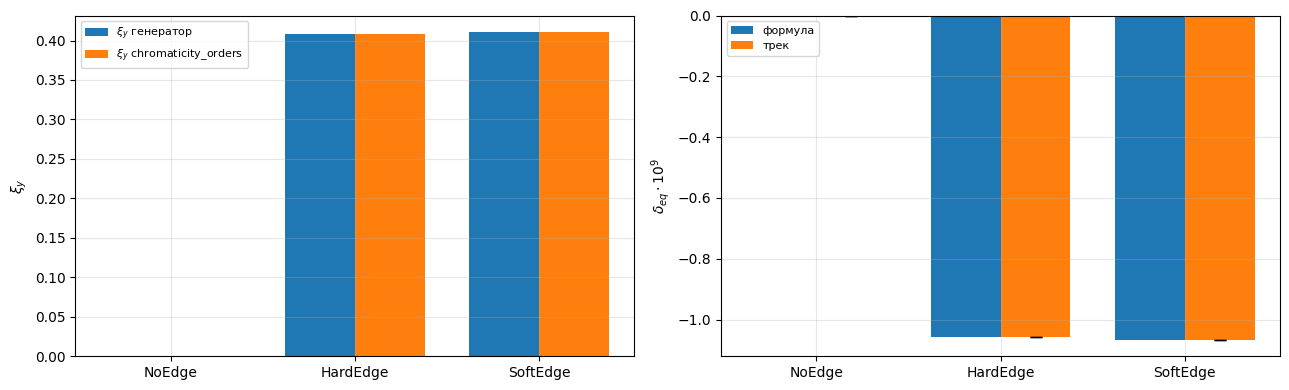

In [16]:
n6 = pd.read_csv(OUT / '06_numbers.csv'); n6 = n6[n6.model != 'setup'].pivot(index='quantity', columns='model', values='value')
M = ['NoEdge', 'HardEdge', 'SoftEdge']
display(n6.loc[['Qx', 'Qy', 'dQy', 'xi_x', 'xi_y', 'xi_orders_y', 'eta1', 'formula_delta_eq', 'track_delta_eq', 'track_unc_delta_eq'], M])
bm = seq[seq.name == 'BM']; h = (bm.angle_closed_rad / bm.length_m).to_numpy()
est = (at('bety_m', np.r_[bm.s0, bm.s1]) * np.r_[h, h]**2).sum() * (0.05 / 6) / (4 * np.pi)
print(f"оценка |ΔQy| = Σ β_y h² ∫F(1−F)dz / 4π = {est:.4e};  BELL SoftEdge: ΔQy = {n6.loc['dQy', 'SoftEdge']:.4e}")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4)); w = .38; x = np.arange(3)
a1.bar(x - w / 2, n6.loc['xi_y', M], w, label=r'$\xi_y$ генератор'); a1.bar(x + w / 2, n6.loc['xi_orders_y', M], w, label=r'$\xi_y$ chromaticity_orders')
a1.set_xticks(x, M); a1.set_ylabel(r'$\xi_y$'); a1.grid(alpha=.3); a1.legend(fontsize=8)
a2.bar(x - w / 2, n6.loc['formula_delta_eq', M] * 1e9, w, label='формула')
a2.bar(x + w / 2, n6.loc['track_delta_eq', M] * 1e9, w, yerr=n6.loc['track_unc_delta_eq', M] * 1e9, capsize=4, label='трек')
a2.set_xticks(x, M); a2.set_ylabel(r'$\delta_{eq}\cdot10^9$'); a2.axhline(0, color='k', lw=.6); a2.grid(alpha=.3); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Рисунок 8.** Слева: вертикальная хроматичность при трёх моделях края (генератор против `chromaticity_orders`). Справа: $\delta_{eq}$
(формула против трека) на силах своего решения шага 5.

**Выводы.**
- Край ломает коррекцию шага 5 только по $\xi_y$: жёсткий край даёт $\xi_y=0.408$ при неизменных тюнах и $\eta_1$, мягкий — $0.411$.
  Генератор и `chromaticity_orders` совпадают до $10^{-6}$.
- $\delta_{eq}$ становится $-1.06\cdot10^{-9}$ — 5.5 % голого значения; формула и трек совпадают до $10^{-3}$ относительно. Значит, для
  $\delta_{eq}\approx0$ секступоли надо решать на факторе **с краем** (достаточно `HardEdge`).
- Мягкий край: $\Delta Q_y=-1.27\cdot10^{-3}$ при $\Delta Q_x\approx-10^{-6}$; простая оценка через $\beta_yh^2\!\int\!F(1-F)$ даёт ту же
  величину. Разница мягкого и жёсткого края в $\xi_y$ (0.7 %) и $\eta_1=-1.0\cdot10^{-4}$ на $\delta_{eq}$ почти не влияет.
- `exact_track_element` не принимает `EdgeMap`; в треке край — фактор Ли порядка 3 (BELL issue #68).

## 7. Нелинейность и динамическая апертура (перекрёстная проверка)
Своё решение шага 5, `NoEdge`. Аналитическая граница — критерий Гиньяра–Хагеля: дробный тюн приближается $p/q$ ($q\le100$, здесь
$\{Q_x\}\approx6/13$), вдоль линейной орбиты $x_n^{(0)}=R^n(x_0,0,0,0,0,\delta)$ перемножаются якобианы карты, и устойчивость требует
$$\Bigl|\operatorname{Tr}\prod_{n=1}^{q}J\bigl(x_n^{(0)}\bigr)\Bigr|<2 .$$
При $x_0=0$ след равен $2\cos(q\mu_x)$. Карта берётся усечённой до степени 2 (только секступоли) и до степени 3.
Трек `exact_track_turn` (300 оборотов, апертура 5 см) — перекрёстная проверка; оба результата показаны рядом, без усреднения.

In [17]:
run_step('07_dynamic_aperture.jl', '07_dynamic_aperture.md')

# Step 7. Dynamic aperture on the own sextupole set, NoEdge.
#
#   julia --project=studies/magnetic_ring studies/magnetic_ring/scripts/07_dynamic_aperture.jl
#
# Rebuild the step-5 placement and set k2 from output/05_sext_strengths.json,
# object k2_per_m3.own. The fringe model is FringeModel() (NoEdge).
#
# Lie readings of that one-turn factor: tunes, distance of n_x Q_x + n_y Q_y
# to an integer, max |f3|, and the optional 6D normal form of the linear-regime
# cavity (h4 / c_ij). The magnetic factor has a longitudinal shear, so the
# 6D normal form is not the transverse reading. Guignard and the track use the
# magnetic factor only.
#
# Guignard boundary (sequential linearisation, |Tr R| < 2):
#   approximate {Q_x} by p/q with q <= 100, minimising |q {Q_x} - p|;
#   linear orbit z_{n+1} = R z_n from (x0, 0, 0, 0, 0, δ);
#   at each of the q points, the one-turn Jacobian of the polynomial map
#   truncated at degree 2 (primary) and degree 3 (secondary);
#   Rprod is the product of the

<details><summary><b>Отчёт <code>output/07_dynamic_aperture.md</code></b></summary>

# Dynamic aperture

NoEdge (`FringeModel()`) on the step-5 own sextupoles. The one-turn object is `ring_lie_factor`. Guignard uses `factor_to_map` truncated at degree 2 and degree 3, then `jacobian_of_map` on the linear orbit of `F.R`. Survival is `exact_track_turn` at the ring start. The two are overlaid and not averaged.

Search window for the trace: 0 to 2.0 m. Aperture cut: 0.05 m. Turns: 300. Step: 0.1 m. q ≤ 100. Runtime 763.9 s.

## Lie readings

Tunes are `optics_along` (integer part included) and μ/2π from `periodic_optics` of the factor. `{Q_x}` is approximated by 6/13, the fraction with q ≤ 100 that minimises |q {Q_x} − p|.

| quantity | value |
| --- | --- |
| Qx | 2.461720e+00 |
| Qy | 2.461337e+00 |
| Qx fractional | 4.617201e-01 |
| Qy fractional | 4.613373e-01 |
| p/q | 6/13 |
| |q Qx_frac − p| | 2.361948e-03 |
| |q Qy_frac − nearest integer| | 2.614800e-03 |
| max |f3| | 1.163649e+02 |
| max |f4| | 7.160297e+02 |
| 2 cos(q μx) | 1.999780e+00 |
| Tr at x0 = 0, degree 3 | 1.999780e+00 |
| αx | -2.519118e-04 |
| βx [m] | 1.936752e+01 |
| coupling | 0.000000e+00 |
| δ_m | 1.000000e-04 |

Distance of the fractional tune to 1/3 and to 1/4, and to the nearest multiple of those families:

| plane | to 1/3 | to 1/4 | nearest third | nearest quarter |
| --- | --- | --- | --- | --- |
| x | 1.283868e-01 | 2.117201e-01 | 1.283868e-01 | 3.827985e-02 |
| y | 1.280040e-01 | 2.113373e-01 | 1.280040e-01 | 3.866268e-02 |

Distance of n_x Q_x + n_y Q_y to the nearest integer. The tunes are the full `optics_along` values.

| resonance | |n·Q − integer| |
| --- | --- |
| 3Qx | 3.851604e-01 |
| 4Qx | 1.531194e-01 |
| 3Qy | 3.840120e-01 |
| 4Qy | 1.546507e-01 |
| 2Qx+Qy | 3.847776e-01 |
| 2Qx-Qy | 4.621030e-01 |
| Qx+2Qy | 3.843948e-01 |
| Qx-2Qy | 4.609545e-01 |
| Qx+Qy | 7.694253e-02 |
| Qx-Qy | 3.828268e-04 |
| 2Qx+2Qy | 1.538851e-01 |
| 2Qx | 7.655970e-02 |
| 2Qy | 7.732535e-02 |
| 3Qx+Qy | 1.535022e-01 |
| 3Qx-Qy | 7.617687e-02 |
| Qx+3Qy | 1.542679e-01 |
| Qx-3Qy | 7.770818e-02 |

Largest |coefficients| of f3:

| monomial | coefficient |
| --- | --- |
| px^3 | 1.163649e+02 |
| px delta^2 | 1.015677e+02 |
| delta^3 | -1.597187e+01 |
| px py^2 | -1.536451e+01 |
| x delta^2 | 5.892759e+00 |
| x px delta | -3.798027e+00 |
| x px^2 | 2.150015e+00 |
| px^2 delta | 1.809104e+00 |

The magnetic factor was not accepted by `dragt_finn_nf6d`: one-turn matrix not stable. The longitudinal block is a shear, so this is the documented rejection (fewer than three elliptic pairs), not a second tune reading.

Optional normal form of `one_turn_factor_rf` at the linear-regime voltage 0.00678732526132278 MV, harmonic 1, BELL phase π. This h4 is not an input of the Guignard scan. `Q_s = |μ_s| / 2π = 1.067379e-03`. max |f3| before the homological step is 1.396936e+00; the cubic residual is 2.220446e-16; |f4 − h4| is 5.868084e-13.

| c_i1 | c_i2 | c_i3 |
| --- | --- | --- |
| -8.587587e+00 | 6.895292e+00 | -8.784327e-04 |
| 0.000000e+00 | -4.053072e-01 | 7.811269e-03 |
| 0.000000e+00 | 0.000000e+00 | 1.121570e-02 |

## Guignard boundary

The linear orbit is R applied to (x0, 0, 0, 0, 0, δ). Rprod is the product of the horizontal 2×2 blocks of the one-turn Jacobian. The boundary below is the stable side of the first crossing of |Tr| = 2. A sample that is stable again after that crossing is listed as re-entrant and does not move the boundary.

| degree | δ | sign | status | first x0 [m] | Tr stable side | largest stable sample [m] |
| --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.000000e+00 | + | first crossing | 8.777416e-03 | 1.9999999999999998e+00 | 1.000000e+00 |
| 2 | 0.000000e+00 | − | first crossing | -8.860764e-03 | 1.9999999999999996e+00 | -9.500000e-01 |
| 2 | 1.000000e-04 | + | first crossing | 8.818307e-03 | 1.9999999999999998e+00 | 1.000000e+00 |
| 2 | 1.000000e-04 | − | first crossing | -8.899778e-03 | 1.9999999999999998e+00 | -9.500000e-01 |
| 2 | -1.000000e-04 | + | first crossing | 8.816194e-03 | 1.9999999999999996e+00 | 1.000000e+00 |
| 2 | -1.000000e-04 | − | first crossing | -8.901448e-03 | 1.9999999999999998e+00 | -9.500000e-01 |
| 3 | 0.000000e+00 | + | first crossing | 4.624863e-01 | -1.9999999999999925e+00 | same |
| 3 | 0.000000e+00 | − | first crossing | -4.621819e-01 | -1.9999999999999976e+00 | same |
| 3 | 1.000000e-04 | + | first crossing | 4.625543e-01 | -1.9999999999999987e+00 | same |
| 3 | 1.000000e-04 | − | first crossing | -4.622474e-01 | -1.9999999999999929e+00 | same |
| 3 | -1.000000e-04 | + | first crossing | 4.624149e-01 | -1.9999999999999918e+00 | same |
| 3 | -1.000000e-04 | − | first crossing | -4.621130e-01 | -1.9999999999999938e+00 | same |

The reported boundary is that first crossing, the edge of the stable interval that contains x0 = 0. Where the largest stable grid sample differs, the trace has become unstable and then stable again. That later sample is not used as the boundary.

## Tracking survival

Launches: 83. Survived all 300 turns: 83. Fraction: 1.000000e+00. The cut is |x| < 0.05 m and |y| < 0.05 m at the ring start, and a finite state vector. The initial condition is the Guignard launch (x0, 0, y0, 0, 0, δ), not a matched Courant–Snyder momentum.

Every launch survived. The outermost survivor is the edge of this grid. No dynamic-aperture loss was observed inside the aperture cut.

| y [m] | δ | sign | last survivor connected to 0 [m] | first loss [m] | re-entrant survivors |
| --- | --- | --- | --- | --- | --- |
| -2.000000e-02 | 0.000000e+00 | − | -2.000000e-02 | none | no |
| -2.000000e-02 | 0.000000e+00 | + | 2.000000e-02 | none | no |
| -1.000000e-02 | 0.000000e+00 | − | -2.000000e-02 | none | no |
| -1.000000e-02 | 0.000000e+00 | + | 2.000000e-02 | none | no |
| 0.000000e+00 | -1.000000e-04 | − | -4.500000e-02 | none | no |
| 0.000000e+00 | -1.000000e-04 | + | 4.500000e-02 | none | no |
| 0.000000e+00 | 0.000000e+00 | − | -4.500000e-02 | none | no |
| 0.000000e+00 | 0.000000e+00 | + | 4.500000e-02 | none | no |
| 0.000000e+00 | 1.000000e-04 | − | -4.500000e-02 | none | no |
| 0.000000e+00 | 1.000000e-04 | + | 4.500000e-02 | none | no |
| 1.000000e-02 | 0.000000e+00 | − | -2.000000e-02 | none | no |
| 1.000000e-02 | 0.000000e+00 | + | 2.000000e-02 | none | no |
| 2.000000e-02 | 0.000000e+00 | − | -2.000000e-02 | none | no |
| 2.000000e-02 | 0.000000e+00 | + | 2.000000e-02 | none | no |

Off-axis launches (y ≠ 0, δ = 0): 20, survived 20.

Phase portraits are the raw turn samples of the exact track at x0 = 5, 10, 20 and 40 mm, y = 0, δ = 0.

## Figures

- `07_da.svg` — degree-2 and degree-3 traces at δ = 0, and the exact survival samples at y = 0. Vertical lines are the |Tr| = 2 boundaries that fall inside the aperture window. Nothing is interpolated between a trace and a survival point.
- `07_phase.svg` — phase portraits.

Tables: `07_numbers.csv`, `07_guignard.csv`, `07_survival.csv`, `07_phase.csv`.


</details>

,значение
Qx_frac,0.46172
Qy_frac,0.461337
p_over_q_p,6
p_over_q_q,13
p_over_q_err,0.00236195
linear_Tr,1.99978
max_abs_f3,116.365
max_abs_f4,716.03
n_launches,83
n_survived,83


запас следа при x0 = 0: 2 − 2cos(qμx) = 2.20e-04;  |Qx − Qy| = 3.83e-04


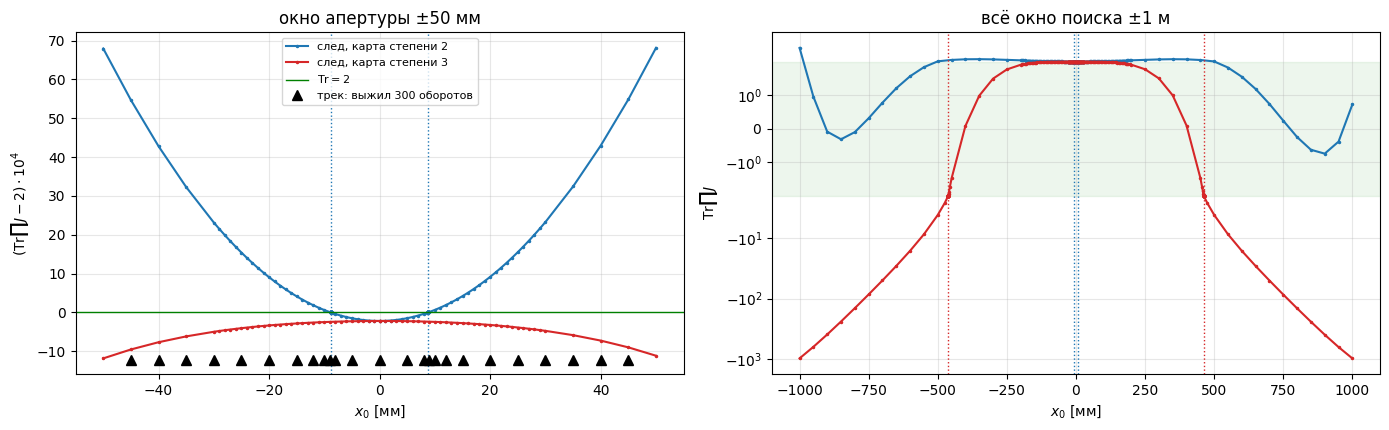

In [18]:
n7 = kv('07_numbers.csv')
display(pd.Series({k: n7[k] for k in ['Qx_frac', 'Qy_frac', 'p_over_q_p', 'p_over_q_q', 'p_over_q_err', 'linear_Tr', 'max_abs_f3', 'max_abs_f4',
                                     'n_launches', 'n_survived']}, name='значение').to_frame())
print(f"запас следа при x0 = 0: 2 − 2cos(qμx) = {2 - n7['linear_Tr']:.2e};  |Qx − Qy| = {abs(n7['Qx_frac'] - n7['Qy_frac']):.2e}")
gu = pd.read_csv(OUT / '07_guignard.csv'); gu = gu[gu.delta == 0]
sv = pd.read_csv(OUT / '07_survival.csv'); s0 = sv[(sv.y0 == 0) & (sv.delta == 0)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, lim, scale in ((ax[0], 0.05, 1e4), (ax[1], 1.0, None)):
    for deg, c in ((2, 'C0'), (3, 'C3')):
        g = gu[(gu.degree == deg) & (gu.kind == 'sample') & (gu.x0.abs() <= lim)].sort_values('x0')
        a.plot(g.x0 * 1e3, (g.tr_horizontal - 2) * scale if scale else g.tr_horizontal, '.-', ms=3, color=c, label=f'след, карта степени {deg}')
        for xb in gu[(gu.degree == deg) & (gu.kind == 'boundary')].x0:
            if abs(xb) <= lim: a.axvline(xb * 1e3, color=c, ls=':', lw=1)
    a.set_xlabel(r'$x_0$ [мм]'); a.grid(alpha=.3)
ax[0].axhline(0, color='g', lw=1, label=r'$\mathrm{Tr}=2$'); ax[0].set_ylabel(r'$(\mathrm{Tr}\prod J-2)\cdot10^4$')
ax[0].plot(s0.x0 * 1e3, np.full(len(s0), .04), 'k^', ms=7, transform=ax[0].get_xaxis_transform(), label='трек: выжил 300 оборотов')
ax[1].axhspan(-2, 2, color='g', alpha=.07); ax[1].set_yscale('symlog', linthresh=2); ax[1].set_ylabel(r'$\mathrm{Tr}\prod J$')
ax[0].set_title('окно апертуры ±50 мм'); ax[1].set_title('всё окно поиска ±1 м'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Рисунок 9.** След произведения якобианов за $q=13$ оборотов вдоль линейной орбиты при $\delta=0$. Слева — окно апертуры,
отклонение следа от 2 (выше нуля — неустойчиво); треугольники — запуски точного трека, все выжили. Справа — всё окно поиска,
зелёная полоса $|\mathrm{Tr}|<2$. Пунктир — первый выход из полосы.

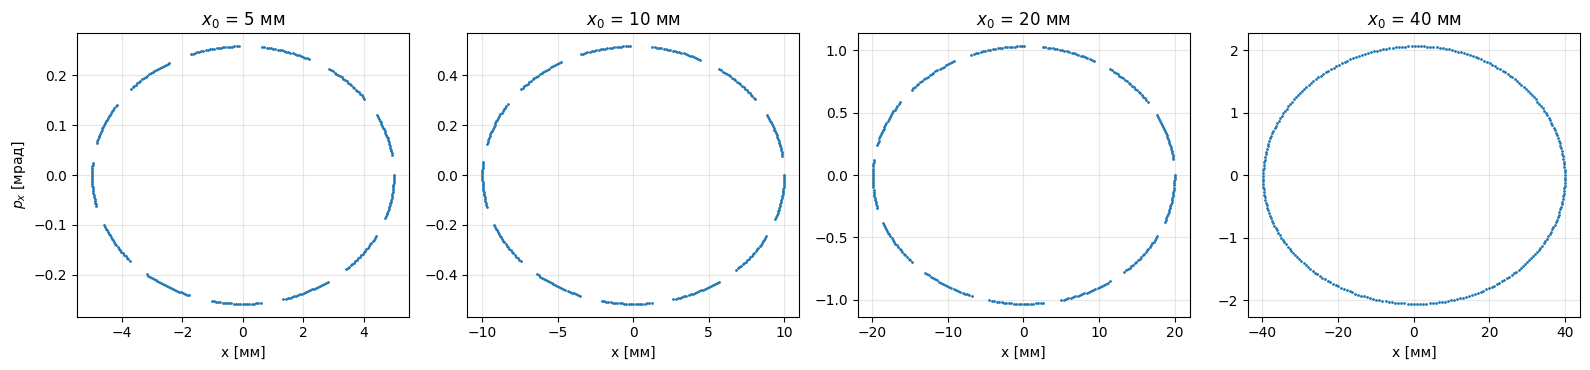

In [19]:
ph = pd.read_csv(OUT / '07_phase.csv')
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, (x0, g) in zip(ax, ph.groupby('x0')):
    a.plot(g.x * 1e3, g.px * 1e3, '.', ms=2); a.set_title(f'$x_0$ = {x0 * 1e3:.0f} мм'); a.set_xlabel('x [мм]'); a.grid(alpha=.3)
ax[0].set_ylabel(r'$p_x$ [мрад]'); plt.tight_layout(); plt.show()

**Рисунок 10.** Фазовые портреты точного трека в начале кольца, $y=0$, $\delta=0$, 300 оборотов.

**Выводы.**
- Резонансы низких порядков далеко: до $1/3$ — 0.128, до $1/4$ — 0.038 (по ближайшему кратному). Портреты — эллипсы без островов
  вплоть до 40 мм; все 83 запуска выжили, потерь внутри апертуры 5 см нет. Штриховой вид портретов при 5–20 мм — это близость к $6/13$:
  за 300 оборотов точки ложатся 13 медленно дрейфующими группами. При 40 мм эллипс заполнен — расстройка от амплитуды уводит тюн от $6/13$.
- Граница Гиньяра по карте степени 2 — $\pm8.8$ мм, по степени 3 — $\pm0.46$ м. **Это расхождение не сглажено.** Рисунок 9 показывает
  механизм: $\{Q_x\}$ лежит в $1.8\cdot10^{-4}$ от $6/13$, поэтому при $x_0=0$ след уже $1.99978$ — запас до границы $2.2\cdot10^{-4}$.
  След степени 2 растёт с амплитудой квадратично и пересекает 2 уже при 9 мм; след степени 3 уходит от 2 вниз, т. е. расстройка
  уводит тюн от $6/13$ — так же, как на портрете 40 мм. В окне ±50 мм с треком согласуется степень 3, а не степень 2; степень 2 ещё и
  возвращается в полосу при $|x_0|>0.5$ м (re-entrant). Вывод: на этом тюне критерий плохо обусловлен и чувствителен к усечению карты,
  а 300 оборотов не разрешают резонанс 13-го порядка. Это гипотеза о механизме, а не выбор победителя.
- Отдельно: $|Q_x-Q_y|=3.8\cdot10^{-4}$ — кольцо сидит на разностном резонансе связи. Без косых элементов связи нет, но любая косая
  ошибка смешает плоскости полностью.

## Итоги
| шаг | результат |
| --- | --- |
| 1 | BM $=\pi/8$, поворот $2\pi$ до $2\cdot10^{-15}$; недогиб исходного файла эквивалентен $\delta\sim1.6\cdot10^{-8}$ |
| 2 | $Q=(2.4617,\,2.4613)$, $\eta_0=-0.534$, $\eta_1=1.017$, $\gamma_t=2.08$; режимы $\hat\phi=0.05$ и $0.3$ |
| 2b | $\xi_1=(-1.46,\,-2.23)$, $\xi_2=(8.55,\,8.10)$ из генераторов, совпадение с series |
| 3 | $\eta_1$ = формула; действия НФ сохраняются, К–С по $x$ нет; двойной учёт полости $\sqrt2$ |
| 4 | $\delta_{eq}=9.53\cdot10^{-9}$ ($J=0$), $1.91\cdot10^{-8}$ (конечные $J$); трек подтверждает $1-\hat\phi^2/32$ |
| 5 | $\xi=\eta_1=0$ тремя семействами; $\delta_{eq}$: $1.9\cdot10^{-8}\to-7\cdot10^{-13}$ (трек); `solve_A` оставляет $6.4\cdot10^{-9}$ |
| 6 | край диполя: $\xi_y=0.41$, $\delta_{eq}=-1.06\cdot10^{-9}$ |
| 7 | трек: 83/83 до 4.5 см; Гиньяр: 8.8 мм (ст. 2) / 0.46 м (ст. 3) |

**Открытые вопросы** (не сглажены, числа не правились):
1. Шаг 4: карта степени 3 не несёт $\hat\phi^2$ в среднем $\delta_{eq}$ — усечение; для кубического режима нужна карта степени ≥ 4.
2. Шаг 5: остаток трека $-7.1\cdot10^{-13}$ после коррекции значим и не описывается главами 1–3.
3. Шаг 7: граница Гиньяра степени 2 (8.8 мм) против трека (без потерь до 45 мм); степень 3 с треком согласуется, критерий на тюне
   в $1.8\cdot10^{-4}$ от $6/13$ плохо обусловлен.

**Следующие шаги.** Решать секступоли на факторе с `HardEdge` (цель $\xi=\eta_1=0$ с краем); длинный трек DA (`LONG_DA=1`) и
чувствительность к выбору $q$; разнести $Q_x$ и $Q_y$ хотя бы на $10^{-2}$, прежде чем вводить ошибки и спин.